# Causas de muerte en Argentina (DEIS, 2005+)

Análisis de las principales causas de defunción a partir del dataset **"Defunciones ocurridas y registradas en la República Argentina"** (DEIS, Ministerio de Salud).

Cada fila es un **agregado** (una combinación de año / jurisdicción / causa / sexo / grupo de edad) con la columna **`cantidad`** = número de muertes. Por eso **todo se pondera por `cantidad`** (nunca contar filas).

**Estructura del análisis**
1. Carga y normalización de columnas
2. Inspección
3. Variables derivadas: capítulo CIE-10, región y grupo de edad ordenado
4. Causas principales — panorama general y a través del tiempo
5. Causas principales — por grupo de edad
6. Causas principales — por región (NOA, NEA, Cuyo, Centro/Pampeana, AMBA, PBA, Patagonia)
7. Causas externas — descomposición por subgrupo (suicidio, sobredosis, homicidio, intención indeterminada)
8-9. Población (denominadores) y tasas por 100.000
10. Diagnóstico de cobertura (CABA / residencia)
11. Notas metodológicas y próximos pasos
12. **Muertes por desesperanza** ("deaths of despair"): suicidio, sobredosis, alcohol, y si la "intención indeterminada" esconde parte de esas muertes

**Advertencias metodológicas**
- *Causa principal* se mide a nivel de **capítulo CIE-10** (agrupamiento estándar); hay además una vista de causas específicas.
- Los **conteos absolutos** por región/edad están confundidos por población. Sirven para rankear causas, pero para comparar "qué mata más" hacen falta **tasas por habitante** y, mejor, **estandarizadas por edad**. El dataset no trae población → ver sección 7.
- **AMBA = solo CABA** y **PBA = provincia de Buenos Aires** como región separada. A nivel provincia PBA incluye el conurbano (GBA) y el interior bonaerense juntos (no se pueden separar aquí).

## 1. Configuración y carga

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['figure.dpi'] = 110

# === EDITAR: ruta a los datos ===
# Puede ser un único .csv o una carpeta con un CSV por año (DEIS publica uno por año).
DATA_PATH = "data/defunciones-ocurridas-y-registradas-en-la-republica-argentina-entre-los-anos-2005-2022.csv"
TOP_N = 8                # cuántas causas mostrar en rankings y tendencias


# --- Helper: eje de tiempo uniforme para todos los gráficos temporales ---
def eje_tiempo(ax, paso=2, rot=45):
    ax.xaxis.set_major_locator(MultipleLocator(paso))
    ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    for t in ax.get_xticklabels():
        t.set_rotation(rot); t.set_ha('right')
    ax.margins(x=0.01)
    return ax


In [2]:
import os, glob
from pathlib import Path

CANON = {  # variantes -> nombre canónico
    'año': 'anio', 'ano': 'anio',
    'jurisdiccion_de_residencia_id': 'jurisdiccion_id', 'jurisdiccion_residencia_id': 'jurisdiccion_id',
    'jurisdicion_residencia_id': 'jurisdiccion_id',
    'jurisdicion_residencia_nombre': 'jurisdiccion_nombre', 'jurisdiccion_residencia_nombre': 'jurisdiccion_nombre',
    'jurisdiccion': 'jurisdiccion_nombre', 'provincia': 'jurisdiccion_nombre',
    'cie10_causa_id': 'cie10_causa', 'causa': 'cie10_causa',
    'grupo_etario': 'grupo_edad', 'edad': 'grupo_edad',
}

def leer_norm(path):
    d = None
    for enc in ('utf-8', 'latin-1'):
        try:
            d = pd.read_csv(path, sep=None, engine='python', encoding=enc); break
        except (UnicodeDecodeError, pd.errors.ParserError):
            continue
    orig = d.columns.tolist()
    d.columns = d.columns.str.strip().str.lower().str.replace(' ', '_')
    d = d.rename(columns={k: v for k, v in CANON.items() if k in d.columns})
    if 'cantidad' not in d.columns: d['cantidad'] = 1
    d['cantidad'] = pd.to_numeric(d['cantidad'], errors='coerce').fillna(0)
    return d, orig


DATA_DIR = Path("data")
files = [os.path.join(DATA_DIR, "defunciones-ocurridas-y-registradas-en-la-republica-argentina-entre-los-anos-2005-2022.csv")]
files += sorted(glob.glob(os.path.join(DATA_DIR, "defuncion2023.csv")))
files += sorted(glob.glob(os.path.join(DATA_DIR, "defuncion2024.csv")))   # si no existe, se ignora solo

partes = []
for f in files:
    d, orig = leer_norm(f)
    anios = sorted(pd.to_numeric(d['anio'], errors='coerce').dropna().astype(int).unique())
    print(f"{os.path.basename(f)[:45]:45} | {len(d):>8,} filas | años {anios[0]}-{anios[-1]}")
    faltan = {'anio','jurisdiccion_nombre','cie10_causa','grupo_edad','cantidad'} - set(d.columns)
    if faltan: print("   ⚠️ faltan columnas clave:", faltan, "| columnas originales:", orig)
    partes.append(d)

df_raw = pd.concat(partes, ignore_index=True, sort=False)

# Chequeo anti-duplicados: ningún año debería aparecer en dos archivos
print("\nMuertes por año (verificá que no haya años inflados por duplicación):")
display(df_raw.groupby('anio')['cantidad'].sum().astype(int))

defunciones-ocurridas-y-registradas-en-la-rep |  825,814 filas | años 2005-2022


defuncion2023.csv                             |   46,534 filas | años 2023-2023


defuncion2024.csv                             |   47,526 filas | años 2024-2024

Muertes por año (verificá que no haya años inflados por duplicación):


anio
2005    293529
2006    292313
2007    315852
2008    302133
2009    304525
2010    318602
2011    319059
2012    319539
2013    326197
2014    325539
2015    333407
2016    352992
2017    341688
2018    336823
2019    341728
2020    376219
2021    436799
2022    397115
2023    353428
2024    376405
Name: cantidad, dtype: int64

## 2. Inspección rápida

In [3]:
print('Años:', sorted(df_raw['anio'].dropna().unique()))
print('\nMuertes totales por año (top/bottom):')
display(df_raw.groupby('anio')['cantidad'].sum().astype(int))

print('\nGrupos de edad crudos:')
print(sorted(df_raw['grupo_edad'].dropna().unique()))

print('\nJurisdicciones:')
cols_j = [c for c in ['jurisdiccion_id', 'jurisdiccion_nombre'] if c in df_raw.columns]
display(df_raw[cols_j].drop_duplicates().sort_values(cols_j[0]).reset_index(drop=True))

df_raw.head()


Años: [np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]

Muertes totales por año (top/bottom):


anio
2005    293529
2006    292313
2007    315852
2008    302133
2009    304525
2010    318602
2011    319059
2012    319539
2013    326197
2014    325539
2015    333407
2016    352992
2017    341688
2018    336823
2019    341728
2020    376219
2021    436799
2022    397115
2023    353428
2024    376405
Name: cantidad, dtype: int64


Grupos de edad crudos:


['01.De a 0  a 14 anios', '02.De 15 a 34 anios', '03.De 35 a 54 anios', '04.De 55 a 74 anios', '05.De 75 anios y mas', '06.Sin especificar']

Jurisdicciones:


,jurisdiccion_id,jurisdiccion_nombre
0,2,Ciudad Autónoma de Buenos Aires
1,6,Buenos Aires
2,10,Catamarca
3,14,Córdoba
4,18,Corrientes
5,22,Chaco
6,26,Chubut
7,30,Entre Ríos
8,34,Formosa
9,38,Jujuy


,anio,jurisdiccion_id,jurisdiccion_nombre,cie10_causa,cie10_clasificacion,sexo_id,sexo,muerte_materna_id,muerte_materna_clasificacion,grupo_edad,cantidad
0,2010,62,Río Negro,P52,Hemorragia intracraneal no traumática del feto...,2,femenino,NaN,NaN,01.De a 0 a 14 anios,1
1,2013,90,Tucumán,R95,Síndrome de la muerte súbita infantil,1,masculino,NaN,NaN,01.De a 0 a 14 anios,5
2,2018,34,Formosa,Q91,Síndrome de Edwards y síndrome de Patau,2,femenino,NaN,NaN,01.De a 0 a 14 anios,1
3,2020,6,Buenos Aires,Q79,Malformaciones congénitas del sistema osteomus...,2,femenino,NaN,NaN,01.De a 0 a 14 anios,3
4,2012,2,Ciudad Autónoma de Buenos Aires,B34,Infección viral de sitio no especificado,1,masculino,NaN,NaN,01.De a 0 a 14 anios,1


## 3. Variables derivadas

- **`capitulo`**: capítulo CIE-10 a partir de `cie10_causa` (agrupamiento estándar de causas).
- **`region`**: NOA / NEA / Cuyo / Centro/Pampeana / AMBA / PBA / Patagonia, mapeada por `jurisdiccion_id`.
- **`edad`** + **`orden_edad`**: etiqueta limpia y clave de orden a partir de `grupo_edad`.

In [4]:
# --- 3a. Capítulo CIE-10 ---
def cie10_capitulo(code):
    if pd.isna(code):
        return 'XXII - Sin especificar'
    m = re.match(r'^\s*([A-Za-z])(\d{1,2})', str(code).strip().upper())
    if not m:
        return 'XXII - Sin especificar'
    L, n = m.group(1), int(m.group(2))
    if L in ('A', 'B'): return 'I - Infecciosas y parasitarias'
    if L == 'C':        return 'II - Tumores (neoplasias)'
    if L == 'D':        return 'II - Tumores (neoplasias)' if n <= 48 else 'III - Sangre e inmunidad'
    if L == 'E':        return 'IV - Endocrinas, nutricionales y metabólicas'
    if L == 'F':        return 'V - Trastornos mentales y del comportamiento'
    if L == 'G':        return 'VI - Sistema nervioso'
    if L == 'H':        return 'VII - Ojo y anexos' if n <= 59 else 'VIII - Oído'
    if L == 'I':        return 'IX - Sistema circulatorio'
    if L == 'J':        return 'X - Sistema respiratorio'
    if L == 'K':        return 'XI - Sistema digestivo'
    if L == 'L':        return 'XII - Piel y tejido subcutáneo'
    if L == 'M':        return 'XIII - Osteomuscular y tej. conjuntivo'
    if L == 'N':        return 'XIV - Genitourinario'
    if L == 'O':        return 'XV - Embarazo, parto y puerperio'
    if L == 'P':        return 'XVI - Afecciones perinatales'
    if L == 'Q':        return 'XVII - Malformaciones congénitas'
    if L == 'R':        return 'XVIII - Síntomas y signos mal definidos'
    if L in ('S', 'T'): return 'XIX - Traumatismos y envenenamientos'
    if L in ('V', 'W', 'X', 'Y'): return 'XX - Causas externas'
    if L == 'Z':        return 'XXI - Factores que influyen en la salud'
    if L == 'U':        return 'XXII - COVID-19 / usos especiales'
    return 'XXII - Sin especificar'


# --- 3b. Región (por jurisdiccion_id INDEC) ---
# CABA (jurisdicción 2) y Buenos Aires provincia (6) como regiones separadas.
# (A nivel provincia no se puede separar el conurbano/GBA del interior bonaerense.)
JURIS_A_REGION = {
    2: 'CABA', 6: 'Buenos Aires',
    14: 'Centro/Pampeana', 82: 'Centro/Pampeana', 30: 'Centro/Pampeana', 42: 'Centro/Pampeana',
    38: 'NOA', 66: 'NOA', 90: 'NOA', 10: 'NOA', 46: 'NOA', 86: 'NOA',
    34: 'NEA', 22: 'NEA', 18: 'NEA', 54: 'NEA',
    50: 'Cuyo', 70: 'Cuyo', 74: 'Cuyo',
    58: 'Patagonia', 62: 'Patagonia', 26: 'Patagonia', 78: 'Patagonia', 94: 'Patagonia',
}
# Respaldo por nombre, por si algún id viene nulo/raro
NOMBRE_A_REGION = {
    'ciudad autónoma de buenos aires': 'CABA', 'caba': 'CABA', 'buenos aires': 'Buenos Aires',
    'córdoba': 'Centro/Pampeana', 'cordoba': 'Centro/Pampeana', 'santa fe': 'Centro/Pampeana',
    'entre ríos': 'Centro/Pampeana', 'entre rios': 'Centro/Pampeana', 'la pampa': 'Centro/Pampeana',
    'jujuy': 'NOA', 'salta': 'NOA', 'tucumán': 'NOA', 'tucuman': 'NOA', 'catamarca': 'NOA',
    'la rioja': 'NOA', 'santiago del estero': 'NOA',
    'formosa': 'NEA', 'chaco': 'NEA', 'corrientes': 'NEA', 'misiones': 'NEA',
    'mendoza': 'Cuyo', 'san juan': 'Cuyo', 'san luis': 'Cuyo',
    'neuquén': 'Patagonia', 'neuquen': 'Patagonia', 'río negro': 'Patagonia', 'rio negro': 'Patagonia',
    'chubut': 'Patagonia', 'santa cruz': 'Patagonia',
    'tierra del fuego': 'Patagonia', 'tierra del fuego, antártida e islas del atlántico sur': 'Patagonia',
}
def asignar_region(row):
    jid = pd.to_numeric(row.get('jurisdiccion_id'), errors='coerce')
    if pd.notna(jid) and int(jid) in JURIS_A_REGION:
        return JURIS_A_REGION[int(jid)]
    nom = str(row.get('jurisdiccion_nombre', '')).strip().lower()
    return NOMBRE_A_REGION.get(nom, 'Sin especificar/Otro')


# --- 3c. Grupo de edad: separa el prefijo numérico ("05.De 75 y más") ---
def limpiar_edad(g):
    if pd.isna(g):
        return (999, 'Sin especificar')
    s = str(g).strip()
    m = re.match(r'^\s*(\d+)\s*[.\-_ ]+\s*(.*)$', s)  # "05.De 75 y más años"
    if m:
        return (int(m.group(1)), m.group(2).strip())
    return (998, s)


df = df_raw.copy()
df['capitulo'] = df['cie10_causa'].map(cie10_capitulo)
df['region'] = df.apply(asignar_region, axis=1)
edad = df['grupo_edad'].map(limpiar_edad)
df['orden_edad'] = edad.map(lambda t: t[0])
df['edad'] = edad.map(lambda t: t[1])

print('Regiones:', df['region'].value_counts(dropna=False).to_dict())
print('\nChequeo mapeo capítulo (muestra):')
display(df[['cie10_causa', 'capitulo']].drop_duplicates().head(10))


Regiones: {'Centro/Pampeana': 201953, 'NOA': 168311, 'Buenos Aires': 141497, 'NEA': 130144, 'Cuyo': 102059, 'Patagonia': 97427, 'CABA': 62459, 'Sin especificar/Otro': 16024}

Chequeo mapeo capítulo (muestra):


,cie10_causa,capitulo
0,P52,XVI - Afecciones perinatales
1,R95,XVIII - Síntomas y signos mal definidos
2,Q91,XVII - Malformaciones congénitas
3,Q79,XVII - Malformaciones congénitas
4,B34,I - Infecciosas y parasitarias
5,P22,XVI - Afecciones perinatales
6,Q89,XVII - Malformaciones congénitas
7,Q25,XVII - Malformaciones congénitas
8,P36,XVI - Afecciones perinatales
9,P25,XVI - Afecciones perinatales


In [5]:
# Helpers de agregación y de heatmap (se usan en todas las secciones)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def guardar_fig(nombre, fig=None):
    # Guarda el gráfico activo (o `fig`) como PNG en figures/.
    slug = re.sub(r'[^a-z0-9]+', '_', nombre.lower()).strip('_')
    (fig or plt.gcf()).savefig(os.path.join(FIG_DIR, f'{slug}.png'), dpi=150, bbox_inches='tight')

def agg(data, cols):
    # Suma cantidad por las columnas dadas -> columna 'muertes'.
    return (data.groupby(cols, dropna=False)['cantidad'].sum()
            .reset_index(name='muertes'))

def share(data, group_cols, causa='capitulo'):
    # % que representa cada causa dentro de cada grupo.
    t = agg(data, group_cols + [causa])
    tot = t.groupby(group_cols)['muertes'].transform('sum')
    t['pct'] = 100 * t['muertes'] / tot
    return t

def heatmap(mat, title, fmt='{:.0f}', cbar_label='%'):
    fig, ax = plt.subplots(figsize=(max(8, 0.7 * mat.shape[1] + 4), 0.55 * mat.shape[0] + 2.5))
    data = mat.values.astype(float)
    im = ax.imshow(data, aspect='auto', cmap='YlOrRd')
    ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns, rotation=40, ha='right')
    ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(mat.index)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = data[i, j]
            if not np.isnan(v):
                ax.text(j, i, fmt.format(v), ha='center', va='center', fontsize=8,
                        color='black' if v < np.nanmax(data) * 0.6 else 'white')
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8, label=cbar_label)
    ax.grid(False)
    plt.tight_layout()
    guardar_fig(title, fig)
    plt.show()

# Base de trabajo (podés filtrar años acá si querés, p.ej. df[df.anio >= 2010])
base = df.copy()
ORDEN_EDAD = (base[['orden_edad', 'edad']].drop_duplicates()
              .sort_values('orden_edad')['edad'].tolist())
print('Grupos de edad ordenados:', ORDEN_EDAD)


Grupos de edad ordenados: ['De a 0  a 14 anios', 'De 15 a 34 anios', 'De 35 a 54 anios', 'De 55 a 74 anios', 'De 75 anios y mas', 'Sin especificar']


## 4. Causas principales — panorama general y a través del tiempo

Ranking por capítulo (todos los años juntos), y luego la **participación (%)** de cada capítulo en el total de muertes de cada año — la participación es más comparable en el tiempo que los conteos, que crecen con la población y el registro.

Principales causas de muerte (capítulo CIE-10), 2005+:


,capitulo,muertes,pct
0,IX - Sistema circulatorio,1938400,28.7
1,II - Tumores (neoplasias),1244043,18.4
2,X - Sistema respiratorio,1121940,16.6
3,XVIII - Síntomas y signos mal definidos,485138,7.2
4,XX - Causas externas,381113,5.6
5,I - Infecciosas y parasitarias,299935,4.4
6,XI - Sistema digestivo,290534,4.3
7,"IV - Endocrinas, nutricionales y metabólicas",240543,3.6
8,XIV - Genitourinario,236463,3.5
9,XXII - COVID-19 / usos especiales,164796,2.4


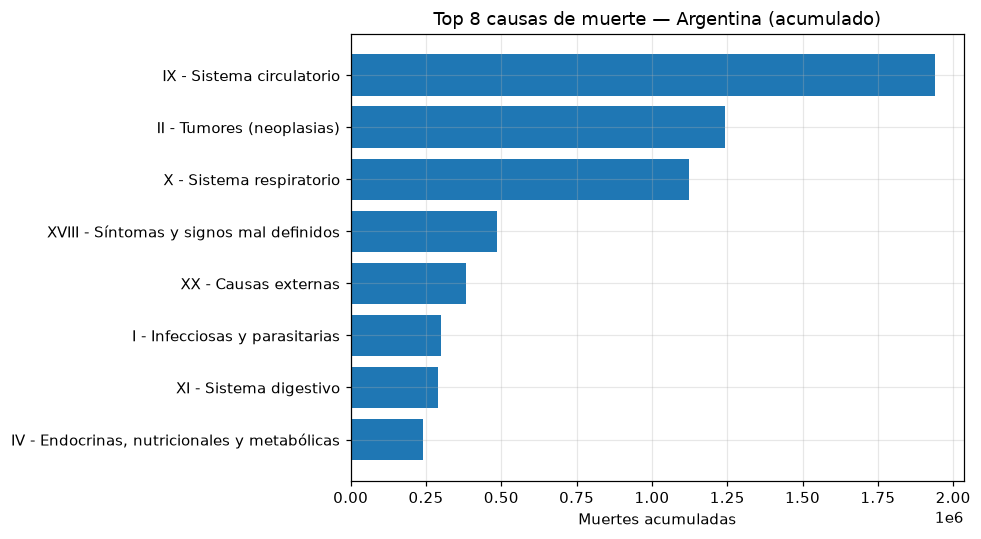

In [6]:
# Ranking general por capítulo (todos los años)
tot = agg(base, ['capitulo']).sort_values('muertes', ascending=False)
tot['pct'] = 100 * tot['muertes'] / tot['muertes'].sum()
print('Principales causas de muerte (capítulo CIE-10), 2005+:')
display(tot.assign(muertes=lambda d: d['muertes'].astype(int),
                   pct=lambda d: d['pct'].round(1)).reset_index(drop=True))

top = tot.head(TOP_N).iloc[::-1]
plt.figure(figsize=(9, 5))
plt.barh(top['capitulo'], top['muertes'])
plt.xlabel('Muertes acumuladas'); plt.title(f'Top {TOP_N} causas de muerte — Argentina (acumulado)')
plt.tight_layout(); guardar_fig('top_causas_muerte'); plt.show()


In [7]:
# Vista fina: causas ESPECÍFICAS (usa la clasificación textual si existe)
causa_col = 'cie10_clasificacion' if 'cie10_clasificacion' in base.columns else 'cie10_causa'
esp = agg(base, [causa_col]).sort_values('muertes', ascending=False).head(20)
esp['pct'] = (100 * esp['muertes'] / tot['muertes'].sum()).round(2)
print(f'Top 20 causas específicas ({causa_col}):')
display(esp.assign(muertes=lambda d: d['muertes'].astype(int)).reset_index(drop=True))


Top 20 causas específicas (cie10_clasificacion):


,cie10_clasificacion,muertes,pct
0,Insuficiencia cardíaca,559966,8.28
1,"Neumonía, organismo no especificado",495574,7.33
2,Infarto agudo del miocardio,334570,4.95
3,Otras causas mal definidas y las no especifica...,323062,4.78
4,"Insuficiencia respiratoria, no clasificada en ...",234516,3.47
5,Otras Sepsis,228624,3.38
6,Tumor maligno de los bronquios y del pulmón,180289,2.67
7,"Accidente vascular encefálico agudo, no especi...",169290,2.50
8,NaN,164835,2.44
9,"Diabetes mellitus, no especificada",131220,1.94


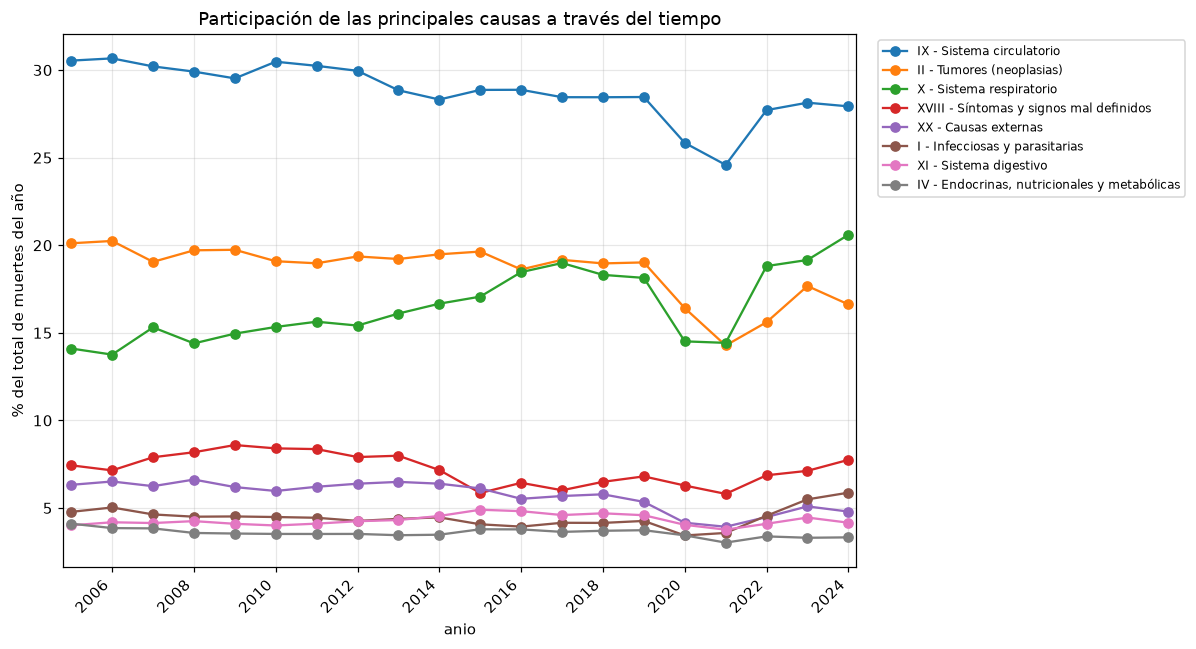

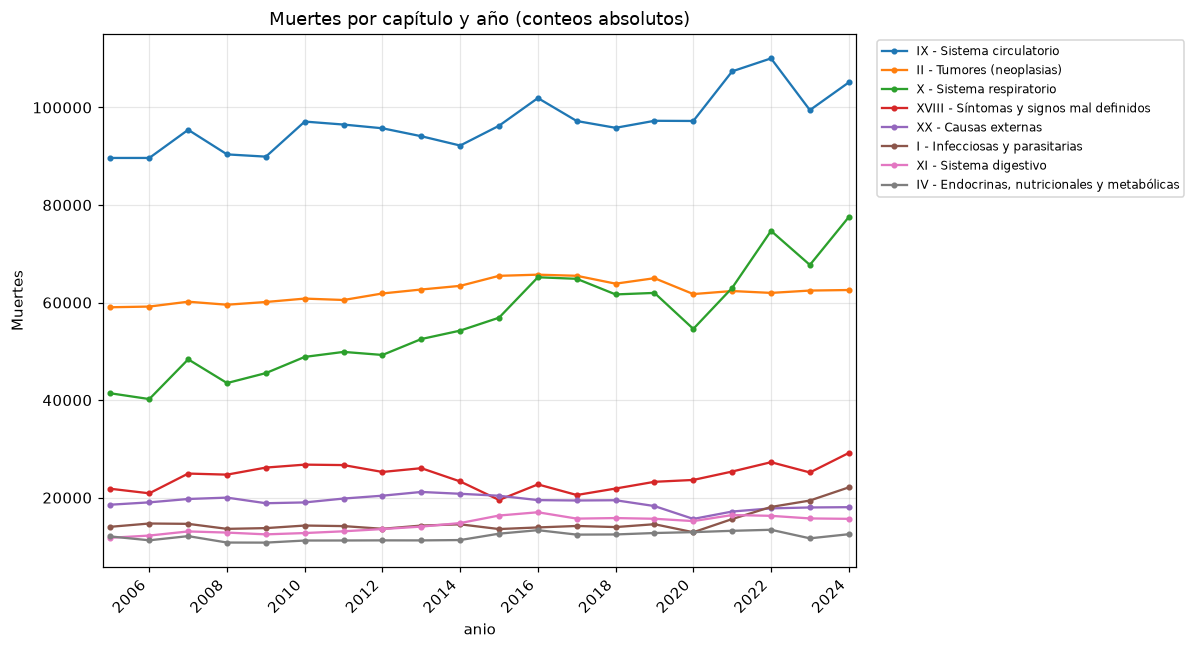

In [8]:
# Tendencia temporal: participación (%) de los principales capítulos por año
top_caps = tot['capitulo'].head(TOP_N).tolist()
serie = share(base, ['anio'])
piv = (serie[serie['capitulo'].isin(top_caps)]
       .pivot(index='anio', columns='capitulo', values='pct')
       .reindex(columns=top_caps))

ax = piv.plot(marker='o', figsize=(11, 6))
ax.set_ylabel('% del total de muertes del año')
ax.set_title('Participación de las principales causas a través del tiempo')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

eje_tiempo(ax)

plt.tight_layout()
guardar_fig('participacion_principales_causas_tiempo')
plt.show()

# También en conteos absolutos, por si interesa el volumen
piv_abs = (agg(base, ['anio', 'capitulo'])
           .query('capitulo in @top_caps')
           .pivot(index='anio', columns='capitulo', values='muertes')
           .reindex(columns=top_caps))
ax = piv_abs.plot(marker='.', figsize=(11, 6))
ax.set_ylabel('Muertes'); ax.set_title('Muertes por capítulo y año (conteos absolutos)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
eje_tiempo(ax)
plt.tight_layout(); guardar_fig('muertes_por_capitulo_anio_absolutos'); plt.show()


## 5. Causas principales — por grupo de edad

El perfil de causas cambia radicalmente con la edad (perinatales/congénitas en la infancia, causas externas en jóvenes, circulatorio y tumores en adultos mayores). El heatmap muestra **qué % de las muertes de cada grupo de edad** explica cada capítulo.

Causa principal por grupo de edad:


,edad,capitulo,muertes,pct
0,De a 0 a 14 anios,XVI - Afecciones perinatales,71531,36.0
1,De 15 a 34 anios,XX - Causas externas,137932,53.5
2,De 35 a 54 anios,II - Tumores (neoplasias),158259,26.1
3,De 55 a 74 anios,IX - Sistema circulatorio,583103,27.0
4,De 75 anios y mas,IX - Sistema circulatorio,1207259,34.4
5,Sin especificar,IX - Sistema circulatorio,6506,25.1


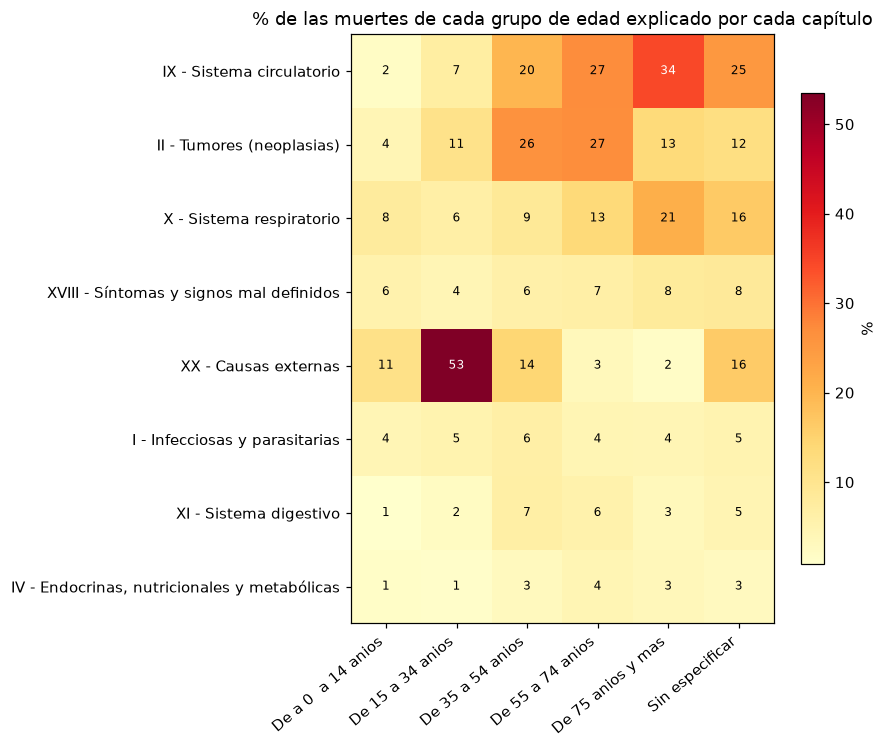

In [9]:
ea = share(base, ['orden_edad', 'edad'])

# Causa #1 en cada grupo de edad
lider_edad = (ea.sort_values('muertes', ascending=False)
              .groupby(['orden_edad', 'edad']).head(1)
              .sort_values('orden_edad')[['edad', 'capitulo', 'muertes', 'pct']])
print('Causa principal por grupo de edad:')
display(lider_edad.assign(muertes=lambda d: d['muertes'].astype(int),
                          pct=lambda d: d['pct'].round(1)).reset_index(drop=True))

# Heatmap: capítulos (filas) x grupos de edad (columnas), % dentro de cada edad
caps_focus = top_caps
m = (ea[ea['capitulo'].isin(caps_focus)]
     .pivot_table(index='capitulo', columns='edad', values='pct')
     .reindex(index=caps_focus, columns=[c for c in ORDEN_EDAD if c in ea['edad'].values]))
heatmap(m, '% de las muertes de cada grupo de edad explicado por cada capítulo')


## 6. Causas principales — por región

NOA, NEA, Cuyo, Centro/Pampeana, AMBA, PBA y Patagonia. Se muestran los conteos (para el ranking) y la **participación (%)** dentro de cada región, que es lo comparable entre regiones de distinto tamaño poblacional.

> Para comparar **niveles** entre regiones (no solo el mix de causas) hacen falta tasas por habitante — ver sección 7.

Top 3 causas por región:


,region,capitulo,muertes,pct
0,Buenos Aires,IX - Sistema circulatorio,838030,30.5
1,Buenos Aires,X - Sistema respiratorio,519030,18.9
2,Buenos Aires,II - Tumores (neoplasias),490128,17.8
3,CABA,IX - Sistema circulatorio,221549,34.2
4,CABA,X - Sistema respiratorio,132608,20.5
5,CABA,II - Tumores (neoplasias),127101,19.6
6,Centro/Pampeana,IX - Sistema circulatorio,424586,29.1
7,Centro/Pampeana,II - Tumores (neoplasias),281812,19.3
8,Centro/Pampeana,X - Sistema respiratorio,193692,13.3
9,Cuyo,IX - Sistema circulatorio,127156,28.9


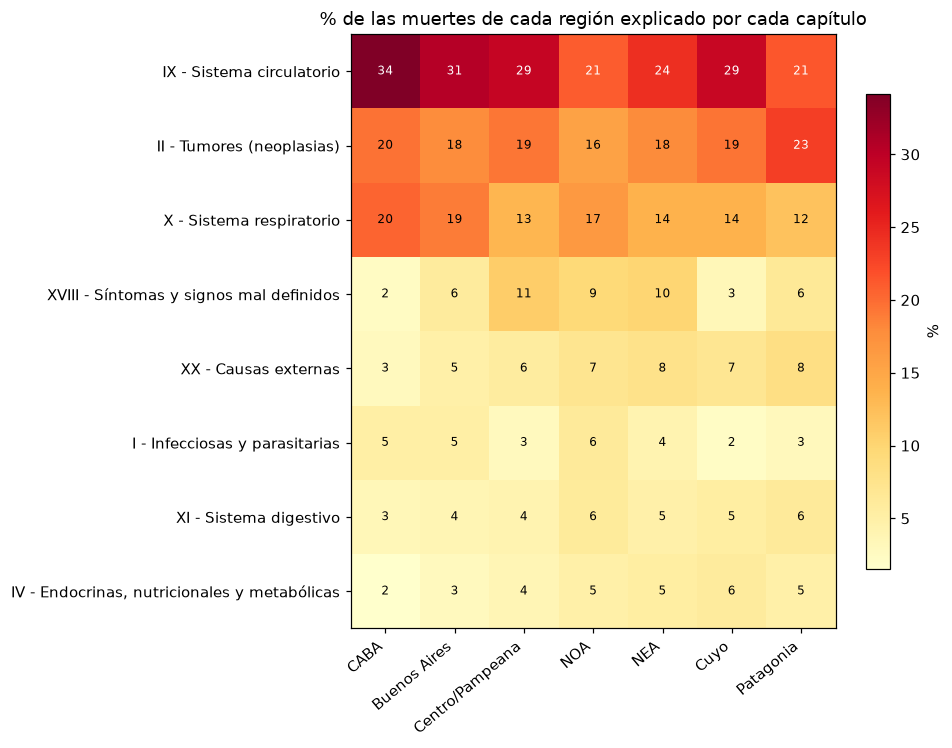

In [10]:
er = share(base, ['region'])
regiones = [r for r in ['CABA', 'Buenos Aires', 'Centro/Pampeana', 'NOA', 'NEA', 'Cuyo', 'Patagonia']
            if r in er['region'].values]

# Causa #1 por región
lider_region = (er.sort_values('muertes', ascending=False)
                .groupby('region').head(3)
                .sort_values(['region', 'muertes'], ascending=[True, False]))
print('Top 3 causas por región:')
display(lider_region.assign(muertes=lambda d: d['muertes'].astype(int),
                            pct=lambda d: d['pct'].round(1)).reset_index(drop=True))

# Heatmap: capítulos x región, % dentro de cada región
mr = (er[er['capitulo'].isin(top_caps)]
      .pivot_table(index='capitulo', columns='region', values='pct')
      .reindex(index=top_caps, columns=regiones))
heatmap(mr, '% de las muertes de cada región explicado por cada capítulo')


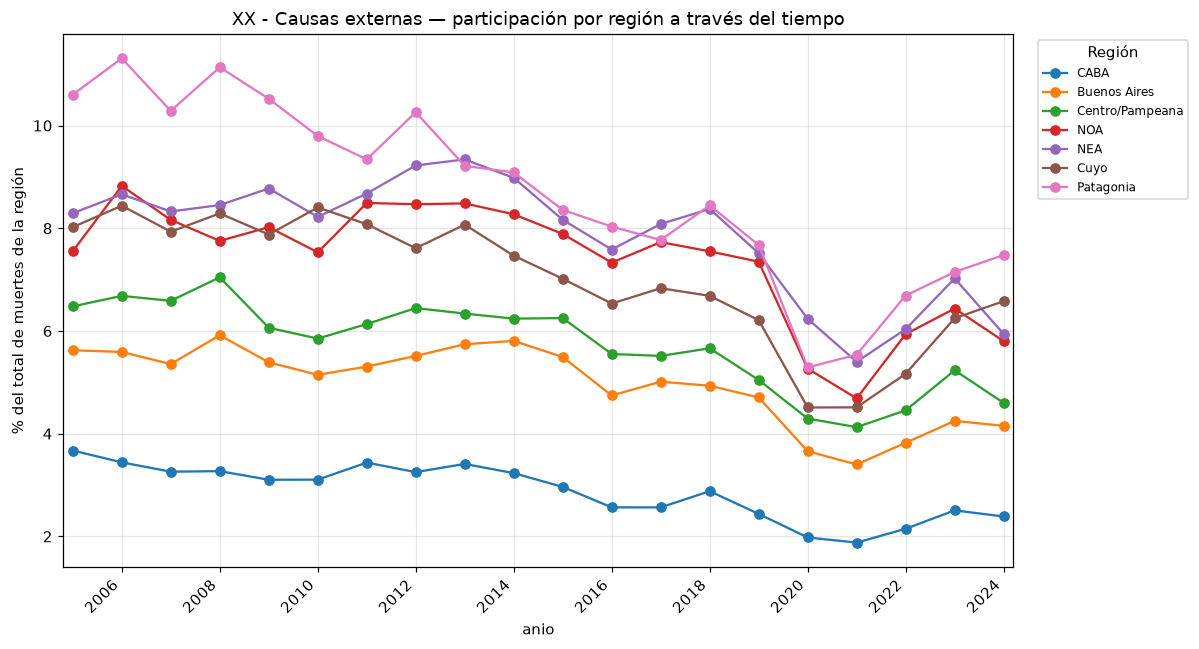

In [11]:
# Tendencia por región para UN capítulo (cambiá la variable para explorar)
CAP = 'XX - Causas externas'   # p.ej. 'IX - Sistema circulatorio', 'II - Tumores (neoplasias)'

sr = share(base, ['anio', 'region'])
piv_r = (sr[sr['capitulo'] == CAP]
         .pivot(index='anio', columns='region', values='pct')
         .reindex(columns=regiones))
ax = piv_r.plot(marker='o', figsize=(11, 6))
ax.set_ylabel(f'% del total de muertes de la región')
ax.set_title(f'{CAP} — participación por región a través del tiempo')
ax.legend(title='Región', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
eje_tiempo(ax)
plt.tight_layout(); guardar_fig('participacion_por_region_capitulo'); plt.show()


## 7. Causas externas — descomposición por subgrupo

Dentro del capítulo XX se separan transporte, suicidio, homicidio, sobredosis, etc. Ojo con *intención indeterminada* como señal de calidad de codificación.

Códigos de causas externas presentes:
['V01', 'V02', 'V03', 'V04', 'V05', 'V06', 'V09', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73', 'V74', 'V75', 'V76', 'V77', 'V78', 'V79', 'V80', 'V81', 'V82', 'V83', 'V84', 'V85', 'V86', 'V87', 'V88', 'V89', 'V90', 'V91', 'V92', 'V93', 'V94', 'V95', 'V96', 'V97', 'V98', 'V99', 'W00', 'W01', 'W02', 'W03', 'W04', 'W05', 'W06', 'W07', 'W08', 'W09', 'W10', 'W11', 'W12', 'W13', 'W14', 'W15', 'W16', 'W17', 'W18', 'W19', 'W20', 'W21', 'W22', 'W23', 'W24', 'W25', 'W26', 'W27', 'W28', 'W29', 'W30', 'W31', 'W32', 'W33', 'W34', 'W35', 'W36', 'W37', 'W38', 'W39', 'W40', 'W

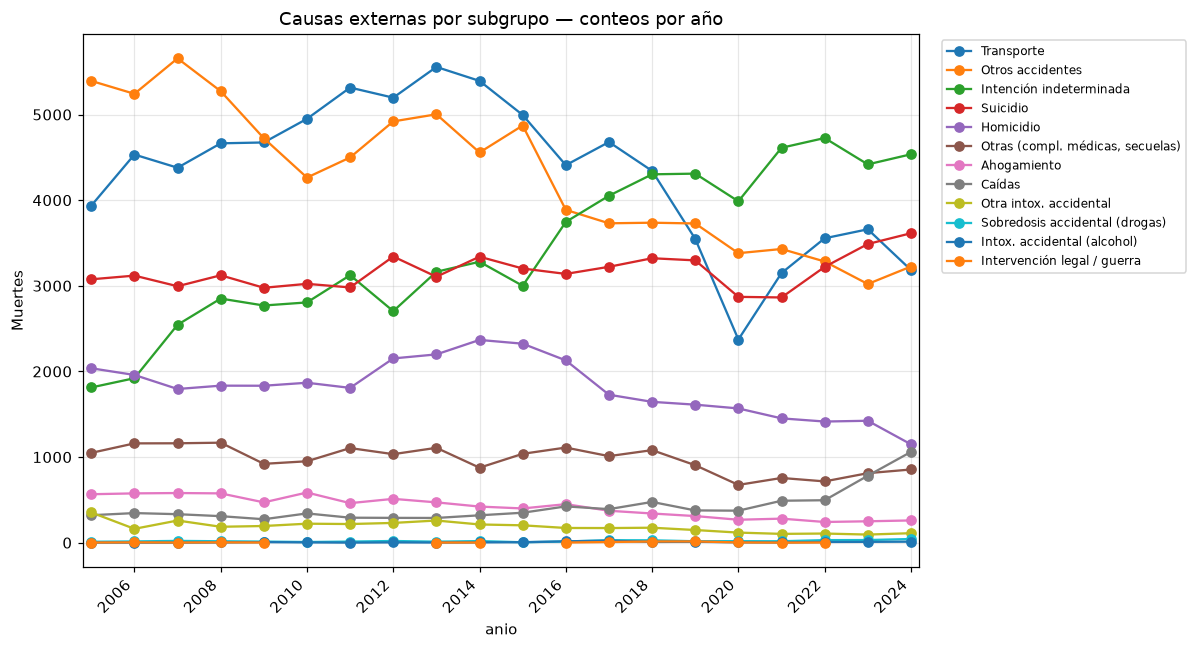

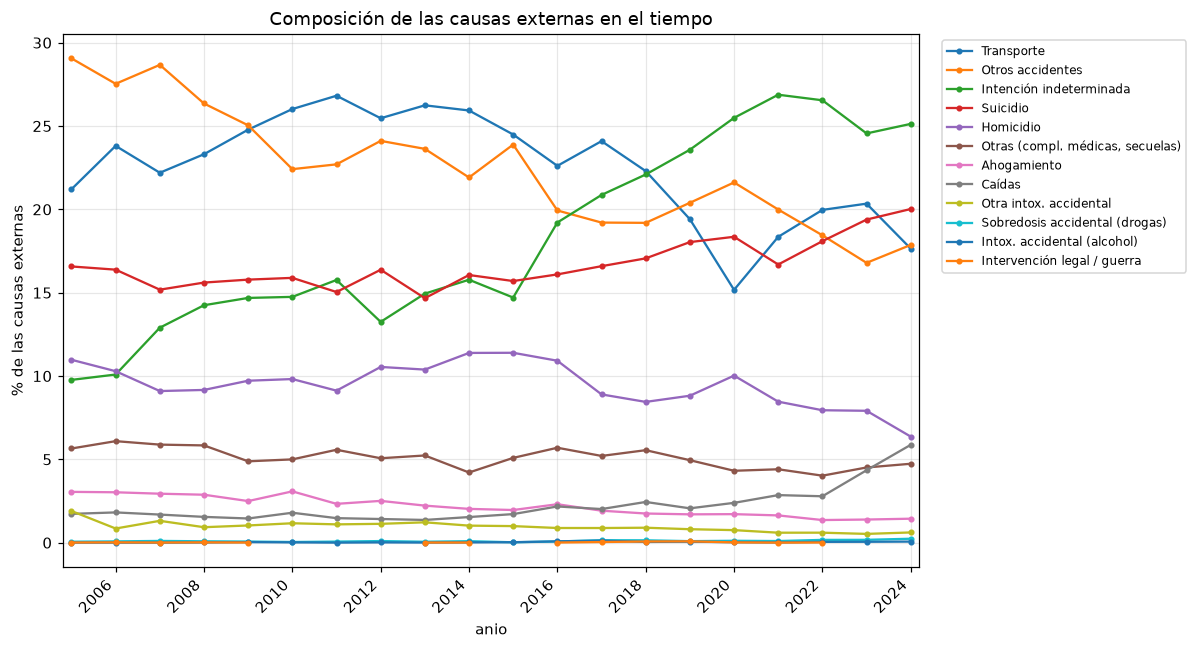

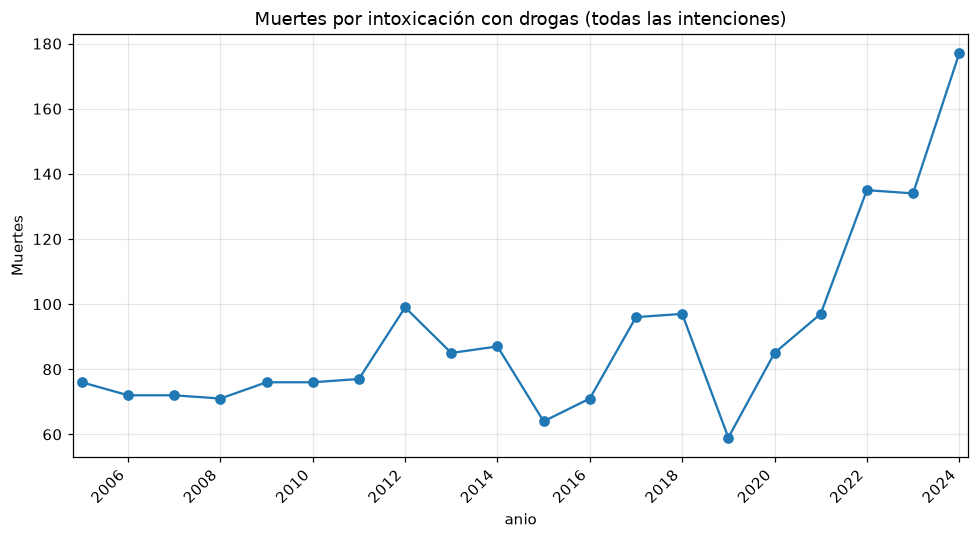

In [12]:
import re

def subgrupo_externa(code):
    m = re.match(r'^\s*([A-Za-z])(\d{1,2})', str(code).strip().upper())
    if not m: return np.nan
    L, n = m.group(1), int(m.group(2))
    if L == 'V':                        return 'Transporte'
    if L == 'W':
        if n <= 19:                     return 'Caídas'
        if 65 <= n <= 74:               return 'Ahogamiento'
        return 'Otros accidentes'
    if L == 'X':
        if 40 <= n <= 44:               return 'Sobredosis accidental (drogas)'
        if n == 45:                     return 'Intox. accidental (alcohol)'
        if 46 <= n <= 49:               return 'Otra intox. accidental'
        if 60 <= n <= 84:               return 'Suicidio'
        if 85 <= n <= 99:               return 'Homicidio'
        return 'Otros accidentes'       # X00-X39, X50-X59 (fuego, calor, naturaleza, etc.)
    if L == 'Y':
        if n <= 9:                      return 'Homicidio'
        if 10 <= n <= 34:               return 'Intención indeterminada'
        if 35 <= n <= 36:               return 'Intervención legal / guerra'
        return 'Otras (compl. médicas, secuelas)'
    return np.nan

ext = base[base['capitulo'] == 'XX - Causas externas'].copy()
ext['subgrupo'] = ext['cie10_causa'].map(subgrupo_externa)

# Chequeo de granularidad: qué códigos externos hay realmente en el dataset
print('Códigos de causas externas presentes:')
print(sorted(ext['cie10_causa'].dropna().unique()))

# --- Conteos absolutos por subgrupo y año ---
piv = agg(ext, ['anio', 'subgrupo']).pivot(index='anio', columns='subgrupo', values='muertes')
orden = piv.sum().sort_values(ascending=False).index
ax = piv[orden].plot(marker='o', figsize=(11, 6))
eje_tiempo(plt.gca())
ax.set_ylabel('Muertes'); ax.set_title('Causas externas por subgrupo — conteos por año')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8); plt.tight_layout(); guardar_fig('causas_externas_subgrupo_conteos_anio'); plt.show()

# --- Composición: % dentro de las causas externas ---
(piv[orden].div(piv.sum(axis=1), axis=0) * 100).plot(marker='.', figsize=(11, 6))
eje_tiempo(plt.gca())
plt.ylabel('% de las causas externas'); plt.title('Composición de las causas externas en el tiempo')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8); plt.tight_layout(); guardar_fig('composicion_causas_externas_tiempo'); plt.show()

# --- Sobredosis por drogas, TODAS las intenciones (estilo CDC) ---
def es_sobredosis_droga(code):
    m = re.match(r'^\s*([A-Za-z])(\d{1,2})', str(code).strip().upper())
    if not m: return False
    L, n = m.group(1), int(m.group(2))
    return (L == 'X' and (40 <= n <= 44 or 60 <= n <= 64 or n == 85)) or (L == 'Y' and 10 <= n <= 14)

od = base[base['cie10_causa'].map(es_sobredosis_droga)]
serie_od = agg(od, ['anio']).set_index('anio')['muertes']
serie_od.plot(marker='o', figsize=(9, 5), title='Muertes por intoxicación con drogas (todas las intenciones)', ylabel='Muertes')
eje_tiempo(plt.gca())

plt.ylabel('Muertes'); plt.tight_layout(); guardar_fig('sobredosis_drogas_todas_intenciones'); plt.show()

## 8. Población (denominadores)

Panel provincial 2005–2024: proyecciones INDEC 2001-based (2005–2009) + 2010-based (2010–2024), verificadas contra totales nacionales.

In [13]:
# === Población 2005-2009 (INDEC proyecciones 2001-based, Ambos sexos) — totales por provincia ===
# Fuente: pegado del PDF Serie Análisis Demográfico N°31, verificado contra total nacional.
POB0509 = {  # provincia: [2005, 2006, 2007, 2008, 2009]
 'Ciudad Autónoma de Buenos Aires': [3018102, 3025772, 3034161, 3042581, 3050728],
 'Buenos Aires': [14654379, 14784007, 14917940, 15052177, 15185336],
 'Catamarca': [365323, 372937, 380612, 388416, 396303],
 'Córdoba': [3254279, 3282680, 3311280, 3340041, 3368609],
 'Corrientes': [980813, 991597, 1002416, 1013443, 1024575],
 'Chaco': [1024934, 1033865, 1042881, 1052185, 1061638],
 'Chubut': [445458, 450549, 455607, 460684, 465750],
 'Entre Ríos': [1217212, 1229373, 1242547, 1255787, 1268979],
 'Formosa': [517506, 524805, 532238, 539883, 547726],
 'Jujuy': [652577, 661667, 670766, 679975, 689231],
 'La Pampa': [321653, 325626, 329576, 333550, 337521],
 'La Rioja': [320602, 327384, 334235, 341207, 348251],
 'Mendoza': [1675309, 1693261, 1711416, 1729660, 1747801],
 'Misiones': [1029645, 1045534, 1061590, 1077987, 1094636],
 'Neuquén': [521439, 530219, 538952, 547742, 556528],
 'Río Negro': [587430, 590871, 594189, 597476, 600688],
 'Salta': [1161484, 1181886, 1202753, 1224022, 1245573],
 'San Juan': [666446, 676189, 685883, 695640, 705378],
 'San Luis': [409280, 418625, 428025, 437544, 447138],
 'Santa Cruz': [213845, 217846, 221871, 225920, 230005],
 'Santa Fe': [3177557, 3199248, 3220818, 3242551, 3264095],
 'Santiago del Estero': [839767, 848196, 856739, 865546, 874519],
 'Tierra del Fuego, Antártida e Islas del Atlántico Sur': [115286, 118899, 122531, 126212, 129929],
 'Tucumán': [1421824, 1439575, 1457357, 1475384, 1493488],
}
NAME2ID = {  # nombre INDEC -> jurisdiccion_id (código INDEC)
 'Ciudad Autónoma de Buenos Aires': 2, 'Buenos Aires': 6, 'Catamarca': 10, 'Córdoba': 14,
 'Corrientes': 18, 'Chaco': 22, 'Chubut': 26, 'Entre Ríos': 30, 'Formosa': 34, 'Jujuy': 38,
 'La Pampa': 42, 'La Rioja': 46, 'Mendoza': 50, 'Misiones': 54, 'Neuquén': 58, 'Río Negro': 62,
 'Salta': 66, 'San Juan': 70, 'San Luis': 74, 'Santa Cruz': 78, 'Santa Fe': 82,
 'Santiago del Estero': 86, 'Tierra del Fuego, Antártida e Islas del Atlántico Sur': 94, 'Tucumán': 90,
}
ANIOS = [2005, 2006, 2007, 2008, 2009]

recs = [(prov, NAME2ID[prov], yr, v) for prov, vals in POB0509.items()
        for yr, v in zip(ANIOS, vals)]
pob0509 = pd.DataFrame(recs, columns=['provincia', 'jurisdiccion_id', 'anio', 'poblacion'])
pob0509['region'] = pob0509['jurisdiccion_id'].map(JURIS_A_REGION)

# --- Verificación: suma nacional por año vs. total INDEC declarado ---
esperado = {2005: 38592150, 2006: 38970611, 2007: 39356383, 2008: 39745613, 2009: 40134425}
chk = pob0509.groupby('anio')['poblacion'].sum()
for yr in ANIOS:
    d = chk[yr] - esperado[yr]
    print(f"{yr}: suma={chk[yr]:>11,}  esperado={esperado[yr]:>11,}  dif={d:+,}  {'OK' if d == 0 else '⚠️'}")

print("\nRegiones sin mapear (debe estar vacío):", pob0509[pob0509['region'].isna()]['provincia'].unique())

2005: suma= 38,592,150  esperado= 38,592,150  dif=+0  OK
2006: suma= 38,970,611  esperado= 38,970,611  dif=+0  OK
2007: suma= 39,356,383  esperado= 39,356,383  dif=+0  OK
2008: suma= 39,745,613  esperado= 39,745,613  dif=+0  OK
2009: suma= 40,134,425  esperado= 40,134,425  dif=+0  OK

Regiones sin mapear (debe estar vacío): <StringArray>
[]
Length: 0, dtype: str


In [14]:
import re

XLS_2010 = "data/c1_proyecciones_prov_2010_2040.xls"
libro = pd.read_excel(XLS_2010, sheet_name=None, header=None, engine='xlrd')

recs = []
for hoja, hdf in libro.items():
    m = re.match(r'\s*(\d{1,2})\s*-', str(hoja))          # id del prefijo de la hoja: '14-CÓRDOBA' -> 14
    if not m:                                             # salta 'GraphData'
        continue
    jid = int(m.group(1))
    if jid == 1:                                          # 01 = Total del país, no lo queremos
        continue
    # localizar la fila de encabezado 'Año | Ambos sexos | Varones | Mujeres'
    hdr = next((r for r in range(min(15, len(hdf)))
                if str(hdf.iat[r, 0]).strip().lower() == 'año'), None)
    if hdr is None:
        print(f"⚠️ {hoja}: no encontré encabezado"); continue
    for r in range(hdr + 1, len(hdf)):
        yr = pd.to_numeric(hdf.iat[r, 0], errors='coerce')
        if pd.isna(yr):
            continue
        yr = int(yr)
        if 2010 <= yr <= 2024:                            # nos quedamos con tu ventana
            recs.append((jid, yr,
                         pd.to_numeric(hdf.iat[r, 1], errors='coerce'),   # ambos
                         pd.to_numeric(hdf.iat[r, 2], errors='coerce'),   # varones
                         pd.to_numeric(hdf.iat[r, 3], errors='coerce')))  # mujeres

pob1024 = pd.DataFrame(recs, columns=['jurisdiccion_id', 'anio', 'ambos', 'varones', 'mujeres'])
pob1024['region'] = pob1024['jurisdiccion_id'].map(JURIS_A_REGION)

# --- Verificaciones ---
print("Provincias:", pob1024['jurisdiccion_id'].nunique(), "| años:",
      pob1024['anio'].min(), "-", pob1024['anio'].max())
print("Sin región (debe ser vacío):", pob1024[pob1024['region'].isna()]['jurisdiccion_id'].unique())
print("¿ambos == varones+mujeres?:",
      (pob1024['ambos'] - pob1024['varones'] - pob1024['mujeres']).abs().max(), "(máx desvío)")
print("\nSuma nacional por año (control):")
display(pob1024.groupby('anio')['ambos'].sum().astype(int))

Provincias: 24 | años: 2010 - 2024
Sin región (debe ser vacío): []
¿ambos == varones+mujeres?: 0 (máx desvío)

Suma nacional por año (control):


anio
2010    40788453
2011    41261490
2012    41733271
2013    42202935
2014    42669500
2015    43131966
2016    43590368
2017    44044811
2018    44494502
2019    44938712
2020    45376763
2021    45808747
2022    46234830
2023    46654581
2024    47067641
Name: ambos, dtype: int64

In [15]:
pob_tot = pd.concat([
    pob0509.rename(columns={'poblacion': 'ambos'})[['jurisdiccion_id', 'anio', 'region', 'ambos']],
    pob1024[['jurisdiccion_id', 'anio', 'region', 'ambos']],
], ignore_index=True).sort_values(['jurisdiccion_id', 'anio']).reset_index(drop=True)

nac = pob_tot.groupby('anio')['ambos'].sum()
print("Total nacional 2005-2024:"); display(nac.astype(int))
print(f"\nSalto 2009->2010: {(nac[2010]/nac[2009]-1)*100:+.2f}%   (esperable ~+1.5%)")
print("Crecimiento medio 2010-2024:", f"{((nac[2024]/nac[2010])**(1/14)-1)*100:.2f}%/año")

Total nacional 2005-2024:


anio
2005    38592150
2006    38970611
2007    39356383
2008    39745613
2009    40134425
2010    40788453
2011    41261490
2012    41733271
2013    42202935
2014    42669500
2015    43131966
2016    43590368
2017    44044811
2018    44494502
2019    44938712
2020    45376763
2021    45808747
2022    46234830
2023    46654581
2024    47067641
Name: ambos, dtype: int64


Salto 2009->2010: +1.63%   (esperable ~+1.5%)
Crecimiento medio 2010-2024: 1.03%/año


## 9. Tasas por 100.000

Muertes / población × 100.000 — el nivel correcto para comparar en el tiempo y entre regiones.

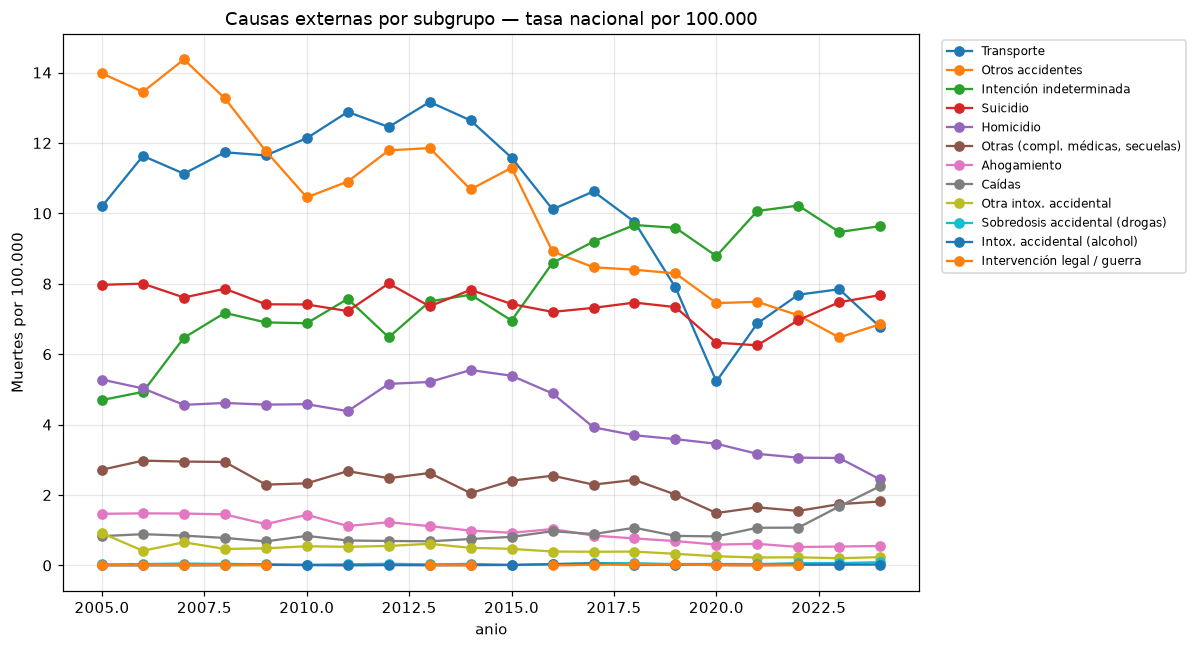

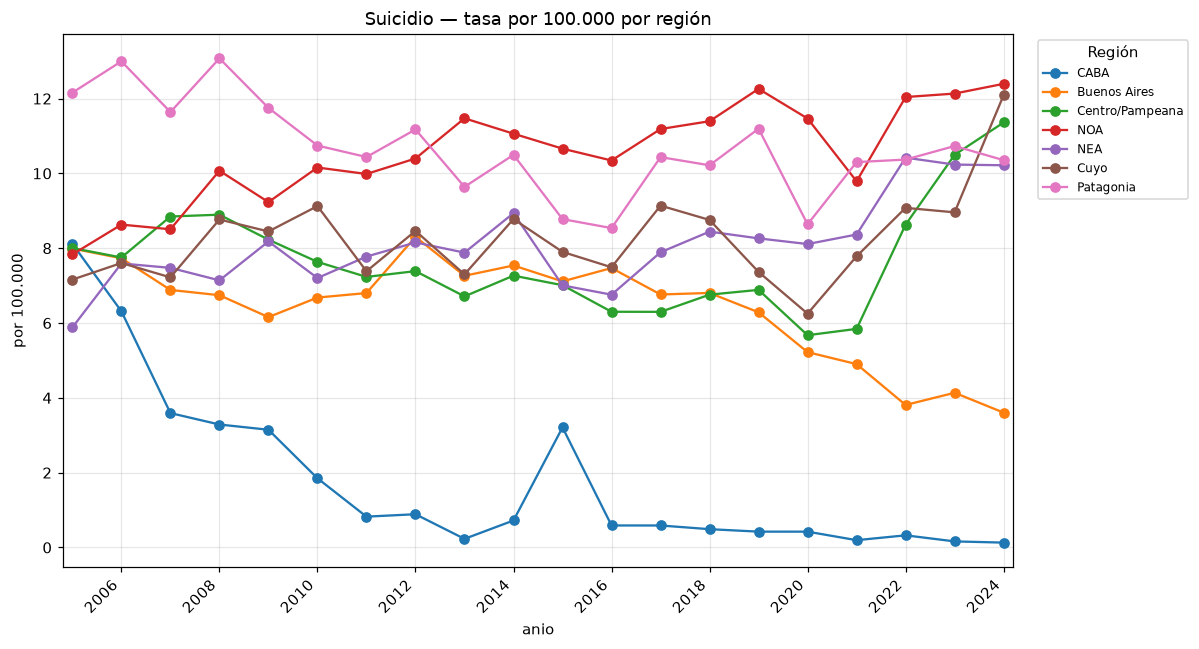

In [16]:
# --- Tasa cruda nacional por subgrupo de causa externa, por 100.000 ---
pob_nac = pob_tot.groupby('anio')['ambos'].sum()

sub_year = agg(ext, ['anio', 'subgrupo']).pivot(index='anio', columns='subgrupo', values='muertes')
tasa = sub_year.div(pob_nac, axis=0) * 100_000
orden = tasa.mean().sort_values(ascending=False).index
ax = tasa[orden].plot(marker='o', figsize=(11, 6))
ax.set_ylabel('Muertes por 100.000'); ax.set_title('Causas externas por subgrupo — tasa nacional por 100.000')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8); plt.tight_layout(); guardar_fig('causas_externas_subgrupo_tasa_100k'); plt.show()

# --- Tasa por región para un subgrupo ---
pob_reg = pob_tot.groupby(['anio', 'region'])['ambos'].sum().reset_index(name='poblacion')
SUB = 'Suicidio'   # o 'Homicidio', 'Transporte', 'Sobredosis accidental (drogas)'
sr = agg(ext[ext['subgrupo'] == SUB], ['anio', 'region']).merge(pob_reg, on=['anio', 'region'])
sr['tasa'] = sr['muertes'] / sr['poblacion'] * 100_000
piv_r = sr.pivot(index='anio', columns='region', values='tasa').reindex(columns=regiones)
ax = piv_r.plot(marker='o', figsize=(11, 6))
eje_tiempo(ax)
ax.set_ylabel('por 100.000'); ax.set_title(f'{SUB} — tasa por 100.000 por región')
ax.legend(title='Región', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8); plt.tight_layout(); guardar_fig(f'{SUB.lower()}_tasa_100k_por_region'); plt.show()

Se colapsan en 'Otras': ['Ahogamiento', 'Caídas', 'Intervención legal / guerra', 'Intox. accidental (alcohol)', 'Otra intox. accidental', 'Sobredosis accidental (drogas)']


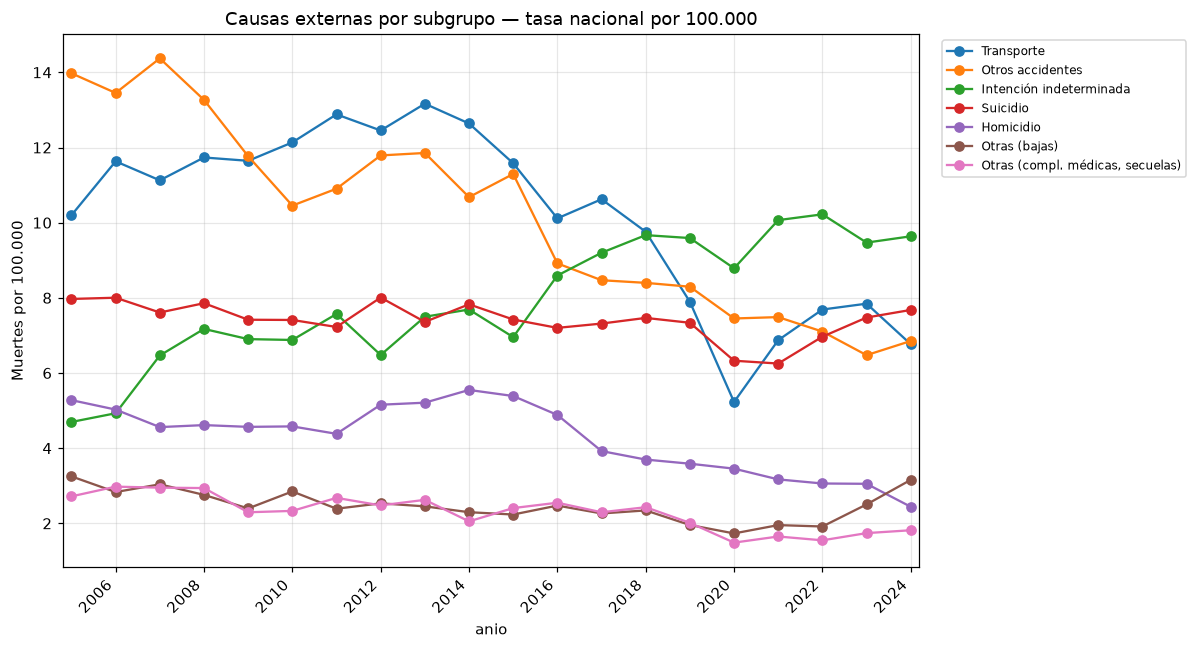

In [17]:
UMBRAL = 1.5   # por 100.000; subí/bajá a gusto
tasa_full = (agg(ext, ['anio', 'subgrupo']).pivot(index='anio', columns='subgrupo', values='muertes')
             .div(pob_nac, axis=0) * 100_000)
chatas = tasa_full.mean()[tasa_full.mean() < UMBRAL].index.tolist()
print("Se colapsan en 'Otras':", chatas)

t = tasa_full.drop(columns=chatas)
t['Otras (bajas)'] = tasa_full[chatas].sum(axis=1)
ax = t[t.mean().sort_values(ascending=False).index].plot(marker='o', figsize=(11, 6))
ax.set_ylabel('Muertes por 100.000'); ax.set_title('Causas externas por subgrupo — tasa nacional por 100.000')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
eje_tiempo(ax)
plt.tight_layout(); guardar_fig('causas_externas_subgrupo_tasa_100k_colapsada'); plt.show()

## 10. Diagnóstico de cobertura (CABA / residencia)

Chequea si la tasa de CABA se desploma por sub-registro de jurisdicción de residencia.

In [18]:
suic_caba = ext[(ext['subgrupo'] == 'Suicidio') & (ext['region'] == 'CABA')]
print("Años con suicidio CABA:", sorted(suic_caba['anio'].unique()))   # ¿faltan 2023-2024?

print("\n(1) Muertes TOTALES residentes CABA, todas las causas (¿estable ~30k?):")
print(base[base['jurisdiccion_id'] == 2].groupby('anio')['cantidad'].sum().astype(int).to_string())

print("\n(2) Causas externas TOTALES CABA (¿cae todo el capítulo o solo suicidio?):")
print(agg(ext[ext['region'] == 'CABA'], ['anio']).set_index('anio')['muertes'].astype(int).to_string())

print("\n(3) Jurisdicción 'Sin especificar/Otro' por año (¿crece = residencia sin asignar?):")
print(base[base['region'] == 'Sin especificar/Otro'].groupby('anio')['cantidad'].sum().astype(int).to_string())

Años con suicidio CABA: [np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]

(1) Muertes TOTALES residentes CABA, todas las causas (¿estable ~30k?):
anio
2005    33691
2006    32949
2007    34422
2008    32074
2009    31458
2010    33111
2011    32298
2012    31560
2013    32133
2014    32400
2015    31714
2016    33136
2017    32053
2018    29723
2019    30895
2020    35569
2021    36201
2022    33331
2023    29489
2024    30117

(2) Causas externas TOTALES CABA (¿cae todo el capítulo o solo suicidio?):
anio
2005    1237
2006    1134
2007    1122
2008    1049
2009     976
2010    1028
2011    1110
2012    1026
2013    1096
2014    1047
2015     940
2016     850
2017     822
2018     856
2019     753
2020     704
2021    

## 11. Notas metodológicas y próximos pasos

**Lo que estos gráficos SÍ dicen:** el *mix* de causas (qué % de las muertes explica cada capítulo) y cómo cambia por edad, región y año. Eso es robusto porque son proporciones internas a cada grupo.

**Lo que NO dicen:** si una región/edad *muere más* que otra. Los conteos absolutos están dominados por el tamaño de población. Para eso hace falta:

1. **Tasas crudas** = muertes / población × 100.000. Necesitás denominadores poblacionales (proyecciones INDEC por provincia-año-sexo-edad, o censos 2010/2022).
2. **Tasas estandarizadas por edad** (directa o indirecta) para comparar regiones sin que el resultado sea solo "esta región tiene población más vieja". Muy relevante en Argentina, donde la estructura etaria varía fuerte entre AMBA/Patagonia y el NEA/NOA.
3. **Mortalidad prematura** (AVPP / YLL) si querés ponderar por edad de muerte — útil para causas externas.

Hook para cuando tengas la población:
```python
# pob: DataFrame con columnas [anio, region (o jurisdiccion_id), edad, poblacion]
# tasas = agg(base, ['anio','region']).merge(pob_region, on=['anio','region'])
# tasas['tasa'] = tasas['muertes'] / tasas['poblacion'] * 100_000
```

**Otros chequeos antes de publicar cualquier número:**
- Capítulo **XVIII (síntomas y signos mal definidos)**: si pesa mucho en alguna región/año, indica problemas de calidad de codificación (mala definición de causa), no epidemiología real.
- **COVID-19** aparece en `U` (capítulo XXII) desde 2020 — ojo al comparar la serie pre/post 2020.
- Verificá si la jurisdicción es de **residencia** u **ocurrencia** (afecta la asignación regional).
- Revisá las columnas `muerte_*` (materna/infantil): si te interesan esos subanálisis, filtran un subconjunto específico.

## 12. Muertes por desesperanza ("deaths of despair")

Case & Deaton (2015, *PNAS*; 2020, *Deaths of Despair and the Future of Capitalism*) documentaron que la mortalidad en la mediana edad (45-54 años) de la población blanca no hispana en EE.UU. dejó de caer —y en algunos grupos aumentó— desde fines de los años '90, empujada por tres causas con una raíz común (desesperanza económica y social, pérdida de sentido/comunidad): **suicidio, sobredosis de drogas/alcohol y enfermedad hepática alcohólica**. El concepto se extendió después a otros países y grupos etarios, con debate sobre si "desesperanza" es la explicación correcta o si pesa más la disponibilidad de opioides/sustancias (Ruhm y otros).

Acá aplicamos el mismo marco a Argentina con los códigos CIE-10 disponibles (que vienen a 3 caracteres, letra + 2 dígitos; no hay subcódigo de 4to dígito). Definimos:

- **Suicidio**: X60–X84 (lesión autoinfligida intencionalmente, cualquier método).
- **Sobredosis/intoxicación, no suicida**: X40–X44 (accidental), X85 (agresión con drogas), Y10–Y14 (intención indeterminada, específicamente por drogas/fármacos) — estilo CDC, mutuamente excluyente con "Suicidio".
- **Alcohol, no suicida**: F10 (trastornos mentales/de conducta por alcohol), K70 (enfermedad hepática alcohólica), X45 (intoxicación accidental por alcohol), Y15 (íd. de intención indeterminada).
- **Intención indeterminada (resto)**: Y16–Y34 — el resto del bloque "intención indeterminada" (ahorcamiento, armas de fuego, ahogamiento, etc. sin intención asignada). Se trata aparte en la sección 12.7, porque es la categoría bajo sospecha del propio análisis.

**Limitación de granularidad**: con códigos a 3 caracteres no se puede aislar, por ejemplo, G31.2 (degeneración nerviosa por alcohol) de G31 completo (que incluye Alzheimer), ni I42.6 (miocardiopatía alcohólica) de I42 completo, ni K86.0 (pancreatitis crónica alcohólica) de K85/K86 completos. Por eso el bloque "Alcohol" de este análisis es un **piso**, no el total real de mortalidad atribuible al alcohol.

In [19]:
# --- 12.1 Clasificación: componentes de "muertes por desesperanza" ---
def _cod3(code):
    m = re.match(r'^\s*([A-Za-z])(\d{1,2})', str(code).strip().upper())
    if not m: return (None, None)
    return m.group(1), int(m.group(2))

def cat_despair(code):
    L, n = _cod3(code)
    if L is None:
        return np.nan
    if L == 'X' and 60 <= n <= 84:
        return 'Suicidio'
    if (L == 'X' and n in (40, 41, 42, 43, 44, 85)) or (L == 'Y' and 10 <= n <= 14):
        return 'Sobredosis (no suicida)'
    if (L == 'F' and n == 10) or (L == 'K' and n == 70) or (L == 'X' and n == 45) or (L == 'Y' and n == 15):
        return 'Alcohol (no suicida)'
    if L == 'Y' and 16 <= n <= 34:
        return 'Indeterminada (resto)'
    return np.nan

base['despair'] = base['cie10_causa'].map(cat_despair)
desp = base[base['despair'].notna()].copy()

CORE = ['Suicidio', 'Sobredosis (no suicida)', 'Alcohol (no suicida)']
core = desp[desp['despair'].isin(CORE)].copy()

print('Muertes 2005-2024 por componente (excluye "Indeterminada (resto)", que se trata aparte en 12.7):')
display(core.groupby('despair')['cantidad'].sum().astype(int).sort_values(ascending=False)
        .rename('muertes').to_frame()
        .assign(pct=lambda d: (100 * d['muertes'] / d['muertes'].sum()).round(1)))

print('\nPara referencia, tamaño del pool "Indeterminada (resto)" (Y16-Y34, no sumado al índice core):')
print(f"{int(desp.loc[desp['despair'] == 'Indeterminada (resto)', 'cantidad'].sum()):,} muertes 2005-2024")


Muertes 2005-2024 por componente (excluye "Indeterminada (resto)", que se trata aparte en 12.7):


,muertes,pct
despair,,
Suicidio,63322,69.4
Alcohol (no suicida),26799,29.4
Sobredosis (no suicida),1176,1.3



Para referencia, tamaño del pool "Indeterminada (resto)" (Y16-Y34, no sumado al índice core):
67,837 muertes 2005-2024


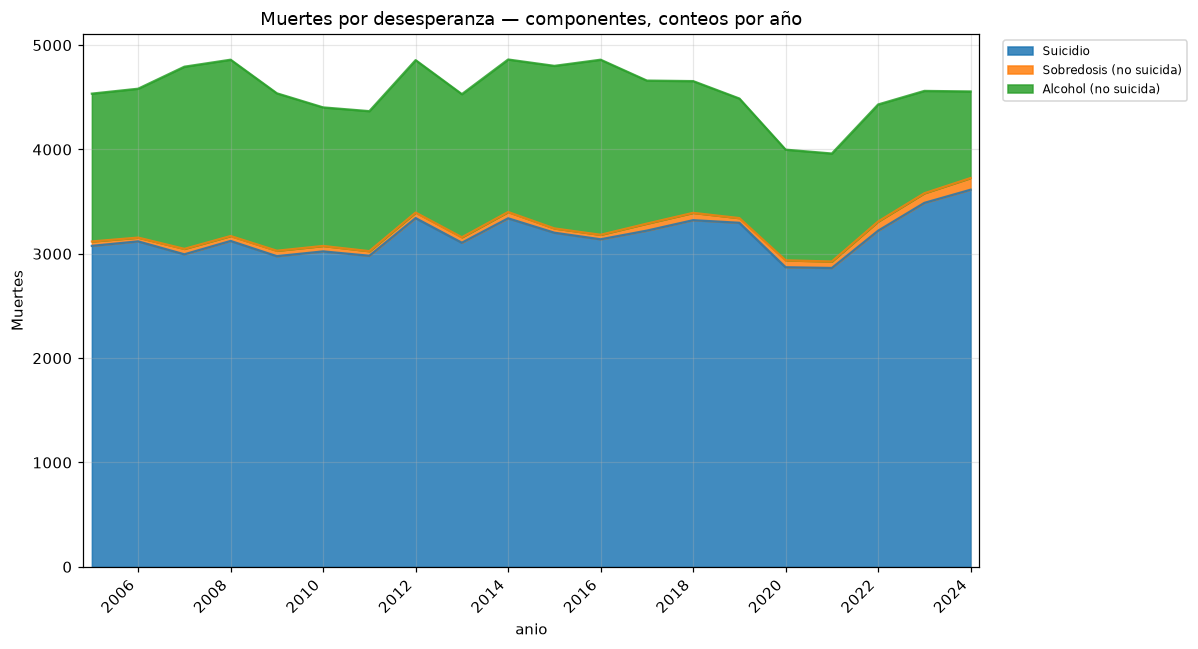

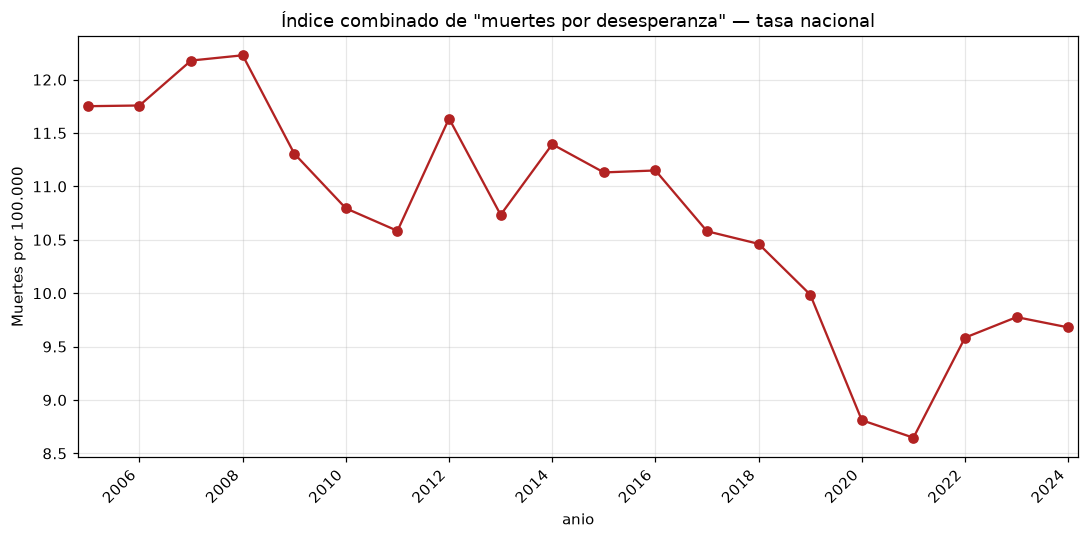

Tasa combinada por 100.000, primer vs. último año disponible:
anio
2005    11.8
2024     9.7
dtype: float64

(A diferencia del patrón ascendente de EE.UU., acá conviene mirar si la serie sube, baja o es plana.)


In [20]:
# --- 12.2 Tendencia nacional: índice combinado y por componente ---
core_year = agg(core, ['anio', 'despair']).pivot(index='anio', columns='despair', values='muertes').fillna(0)
core_year = core_year[CORE]

ax = core_year.plot.area(figsize=(11, 6), alpha=0.85)
ax.set_ylabel('Muertes'); ax.set_title('Muertes por desesperanza — componentes, conteos por año')
ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
eje_tiempo(ax); plt.tight_layout(); guardar_fig('despair_componentes_conteos_anio'); plt.show()

tasa_core = core_year.sum(axis=1) / pob_nac * 100_000
ax = tasa_core.plot(marker='o', figsize=(10, 5), color='firebrick')
ax.set_ylabel('Muertes por 100.000'); ax.set_title('Índice combinado de "muertes por desesperanza" — tasa nacional')
eje_tiempo(ax); plt.tight_layout(); guardar_fig('despair_indice_combinado_tasa_nacional'); plt.show()

print('Tasa combinada por 100.000, primer vs. último año disponible:')
print(tasa_core.round(1).iloc[[0, -1]])
print('\n(A diferencia del patrón ascendente de EE.UU., acá conviene mirar si la serie sube, baja o es plana.)')


### 12.3 Perfil etario

El dataset agrupa la edad en tramos amplios (0-14, 15-34, 35-54, 55-74, 75+), demasiado gruesos para replicar el foco de Case-Deaton en 45-54 años exactos, y no hay población desagregada por edad para calcular una tasa por habitante. Lo que sí se puede ver: **qué % de TODAS las muertes de cada tramo etario** explica el índice "despair" — una medida de peso relativo, no de tasa absoluta.

% de las muertes de cada grupo de edad explicado por el índice "despair" (suicidio+sobredosis+alcohol):


,edad,despair,total,pct
0,De a 0 a 14 anios,1288,198633,0.65
1,De 15 a 34 anios,31226,257915,12.11
2,De 35 a 54 anios,24909,605982,4.11
3,De 55 a 74 anios,25606,2161225,1.18
4,De 75 anios y mas,7588,3514241,0.22
5,Sin especificar,680,25896,2.63


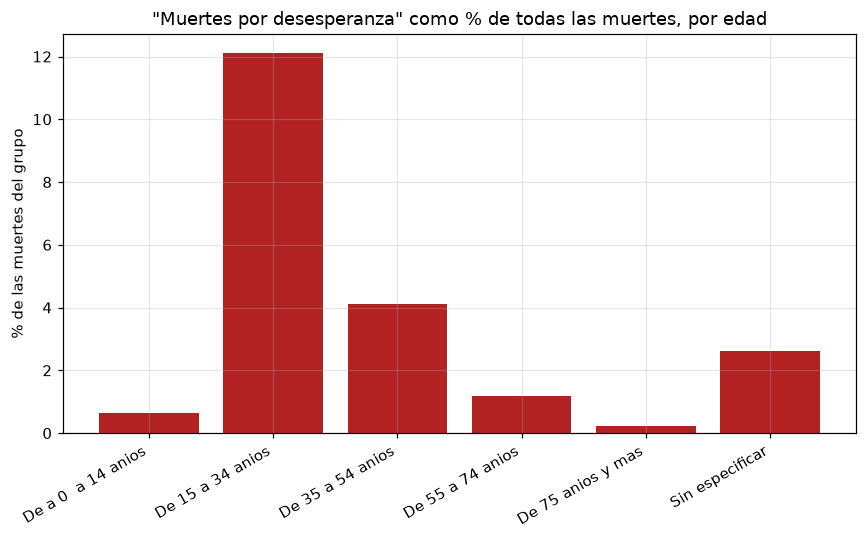

Si el pico está en 15-34 (no en 35-54 como en el hallazgo original de EE.UU.), es un despair juvenil más que de mediana edad — vale la pena chequearlo también contra la tabla de la sección 5.


In [21]:
tot_edad = agg(base, ['orden_edad', 'edad']).rename(columns={'muertes': 'total'})
desp_edad = agg(core, ['orden_edad', 'edad']).rename(columns={'muertes': 'despair'})
e = (tot_edad.merge(desp_edad, on=['orden_edad', 'edad'], how='left').fillna(0)
     .sort_values('orden_edad'))
e['pct'] = 100 * e['despair'] / e['total']

print('% de las muertes de cada grupo de edad explicado por el índice "despair" (suicidio+sobredosis+alcohol):')
display(e[['edad', 'despair', 'total', 'pct']].assign(
    despair=lambda d: d['despair'].astype(int), total=lambda d: d['total'].astype(int),
    pct=lambda d: d['pct'].round(2)).reset_index(drop=True))

plt.figure(figsize=(8, 5))
plt.bar(e['edad'], e['pct'], color='firebrick')
plt.ylabel('% de las muertes del grupo')
plt.title('"Muertes por desesperanza" como % de todas las muertes, por edad')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); guardar_fig('despair_pct_por_edad'); plt.show()

print('Si el pico está en 15-34 (no en 35-54 como en el hallazgo original de EE.UU.), es un despair '
      'juvenil más que de mediana edad — vale la pena chequearlo también contra la tabla de la sección 5.')


### 12.4 Brecha por sexo

La literatura de EE.UU. encuentra que el fenómeno golpea desproporcionadamente a varones. Comparamos tasas por 100.000 usando población de varones/mujeres (proyecciones INDEC, desagregadas por sexo sólo desde 2010 — ver sección 8).

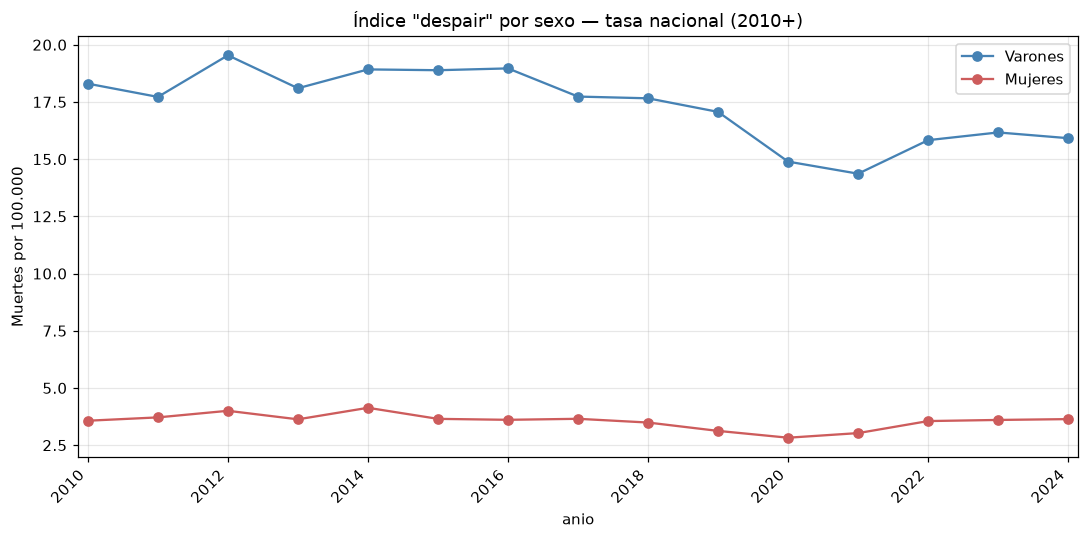

Razón varones/mujeres, tasa por 100.000:
anio
2010    5.13
2011    4.77
2012    4.88
2013    4.99
2014    4.58
2015    5.17
2016    5.26
2017    4.86
2018    5.06
2019    5.46
2020    5.27
2021    4.74
2022    4.45
2023    4.49
2024    4.37
dtype: float64


In [22]:
pob_sexo = pob1024.groupby('anio')[['varones', 'mujeres']].sum()

core_sexo = (agg(core[core['sexo'].isin(['masculino', 'femenino'])], ['anio', 'sexo'])
             .pivot(index='anio', columns='sexo', values='muertes').fillna(0))
core_sexo = core_sexo.loc[core_sexo.index >= 2010]

tasa_sexo = pd.DataFrame({
    'Varones': core_sexo['masculino'] / pob_sexo['varones'] * 100_000,
    'Mujeres': core_sexo['femenino'] / pob_sexo['mujeres'] * 100_000,
})
ax = tasa_sexo.plot(marker='o', figsize=(10, 5), color=['steelblue', 'indianred'])
ax.set_ylabel('Muertes por 100.000'); ax.set_title('Índice "despair" por sexo — tasa nacional (2010+)')
eje_tiempo(ax); plt.tight_layout(); guardar_fig('despair_tasa_por_sexo'); plt.show()

print('Razón varones/mujeres, tasa por 100.000:')
print((tasa_sexo['Varones'] / tasa_sexo['Mujeres']).round(2))


### 12.5 Geografía

Tasa combinada por 100.000 por región, y qué componente pesa más en cada una.

Índice "despair" acumulado 2005-2024 por región (tasa media por 100.000):


,muertes,poblacion,tasa_media
region,,,
Patagonia,8955,46283651,19.3
NOA,16816,106666083,15.8
NEA,10761,79138835,13.6
Cuyo,7738,61682185,12.5
Centro/Pampeana,18302,172397681,10.6
Buenos Aires,26615,329541214,8.1
CABA,1586,61088103,2.6


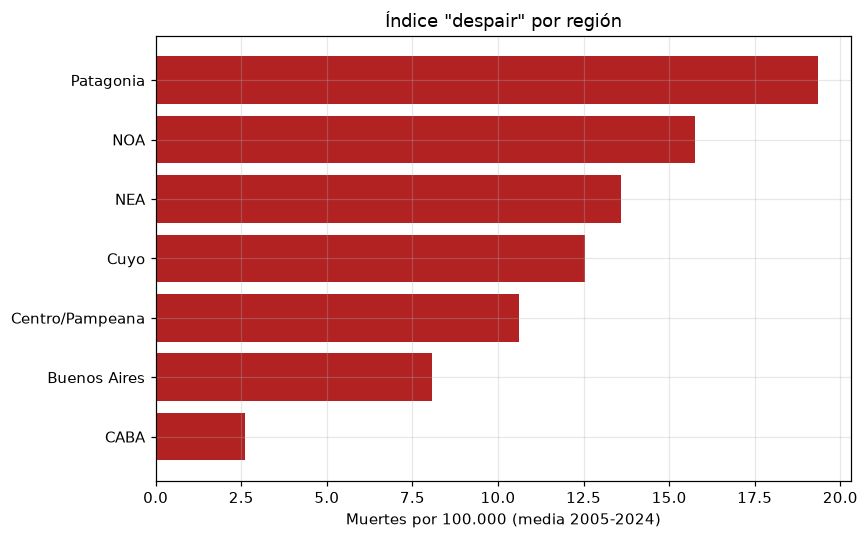

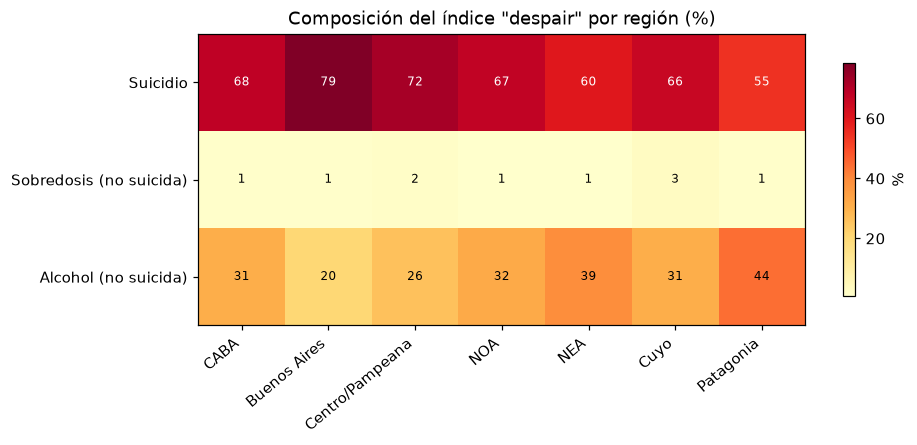

In [23]:
pob_reg = pob_tot.groupby(['anio', 'region'])['ambos'].sum().reset_index(name='poblacion')
core_reg = agg(core, ['anio', 'region']).merge(pob_reg, on=['anio', 'region'])

rank_reg = core_reg.groupby('region')[['muertes', 'poblacion']].sum()
rank_reg['tasa_media'] = rank_reg['muertes'] / rank_reg['poblacion'] * 100_000
rank_reg = rank_reg.reindex(regiones).sort_values('tasa_media', ascending=False)

print('Índice "despair" acumulado 2005-2024 por región (tasa media por 100.000):')
display(rank_reg.assign(muertes=lambda d: d['muertes'].astype(int),
                         tasa_media=lambda d: d['tasa_media'].round(1)))

plt.figure(figsize=(8, 5))
plt.barh(rank_reg.index[::-1], rank_reg['tasa_media'][::-1], color='firebrick')
plt.xlabel('Muertes por 100.000 (media 2005-2024)'); plt.title('Índice "despair" por región')
plt.tight_layout(); guardar_fig('despair_tasa_por_region'); plt.show()

# Composición: qué componente pesa más en cada región
er_desp = share(core, ['region'], causa='despair')
mr = (er_desp.pivot_table(index='despair', columns='region', values='pct')
      .reindex(index=CORE, columns=regiones))
heatmap(mr, 'Composición del índice "despair" por región (%)')


### 12.7 "Intención indeterminada": ¿suicidios escondidos?

En la sección 7 ya se ve que **Y10-Y34 (intención indeterminada)** es, en volumen, comparable o mayor al suicidio confirmado (X60-X84) — y viene creciendo más rápido. La literatura de estadísticas vitales (Rockett et al., sobre "muertes equívocas"/*hidden suicides*; recomendaciones de la OMS sobre calidad del dato de suicidio) documenta que una fracción de las muertes codificadas como "intención indeterminada" son, en la práctica, suicidios que no llegaron a clasificarse como tales — por falta de investigación forense, por estigma social/religioso/de seguro de vida en torno al suicidio, o por criterios de certificación médica más laxos que los de otras causas.

Tres chequeos posibles con este dataset:

1. La evolución del **ratio indeterminada/suicidio** en el tiempo.
2. Si el **mix de mecanismos** (ahorcamiento, arma de fuego, envenenamiento, etc.) dentro de "indeterminada" se parece más al de suicidio confirmado o al de accidentes genuinos.
3. Si hay un **patrón geográfico** que sugiera prácticas de clasificación distintas entre jurisdicciones.

Ninguno de estos chequeos "prueba" causalidad a nivel de un caso individual — son señales agregadas, consistentes con la hipótesis pero no una auditoría de historias clínicas o forenses.

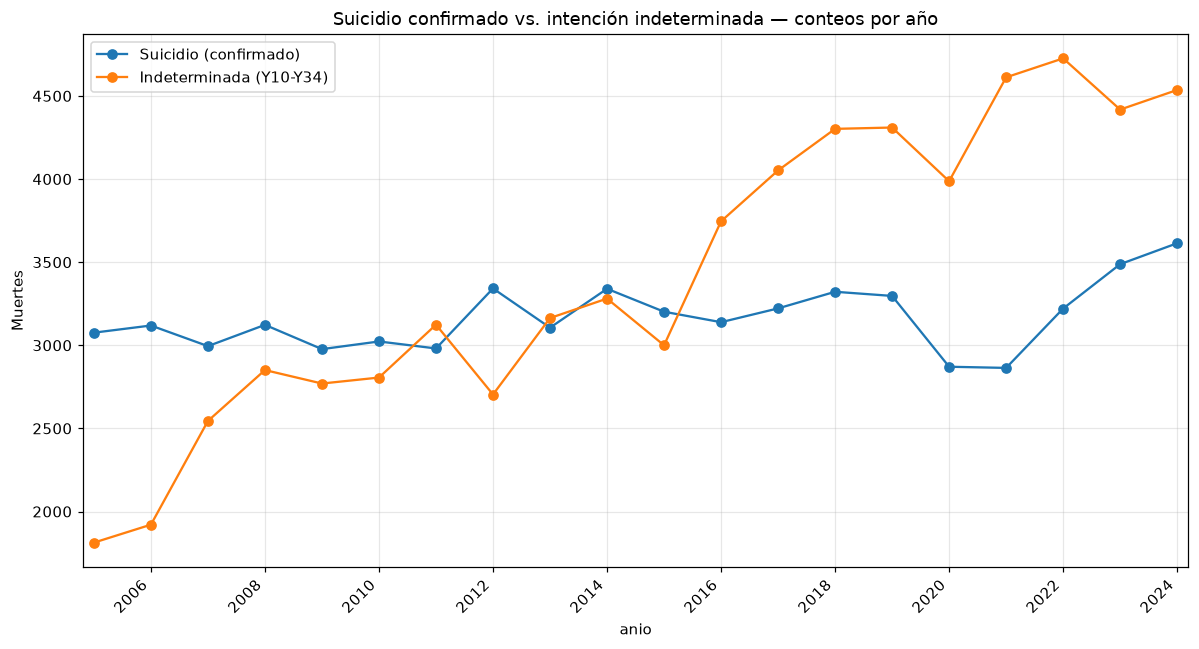

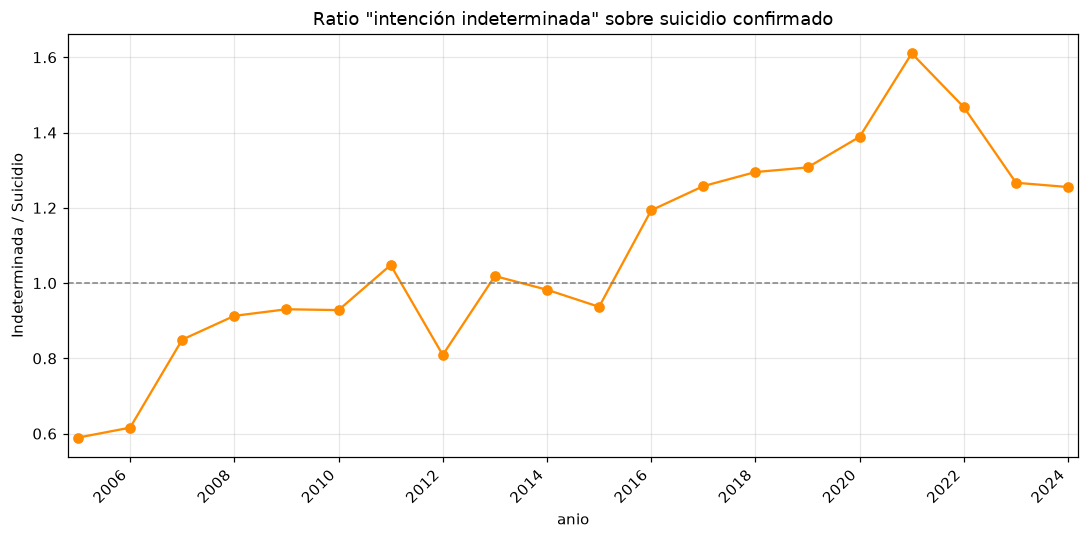

En 2005, había 0.59 muertes de intención indeterminada por cada suicidio confirmado.
En 2024, la relación es 1.26 — el pool de indeterminada creció más rápido que el suicidio confirmado.


In [24]:
# --- 12.7.1 Ratio indeterminada / suicidio en el tiempo ---
suic_year = agg(base[base['cie10_causa'].str.match(r'^X(6[0-9]|7[0-9]|8[0-4])$', na=False)],
                 ['anio']).set_index('anio')['muertes']
indet_year = agg(base[base['cie10_causa'].str.match(r'^Y([1-2][0-9]|3[0-4])$', na=False)],
                  ['anio']).set_index('anio')['muertes']

cmp_year = pd.DataFrame({'Suicidio (confirmado)': suic_year, 'Indeterminada (Y10-Y34)': indet_year})
ax = cmp_year.plot(marker='o', figsize=(11, 6))
ax.set_ylabel('Muertes'); ax.set_title('Suicidio confirmado vs. intención indeterminada — conteos por año')
eje_tiempo(ax); plt.tight_layout(); guardar_fig('suicidio_vs_indeterminada_conteos_anio'); plt.show()

ratio = indet_year / suic_year
ax = ratio.plot(marker='o', figsize=(10, 5), color='darkorange')
ax.axhline(1, color='gray', ls='--', lw=1)
ax.set_ylabel('Indeterminada / Suicidio'); ax.set_title('Ratio "intención indeterminada" sobre suicidio confirmado')
eje_tiempo(ax); plt.tight_layout(); guardar_fig('ratio_indeterminada_sobre_suicidio'); plt.show()

print(f"En {ratio.index[0]}, había {ratio.iloc[0]:.2f} muertes de intención indeterminada por cada suicidio confirmado.")
print(f"En {ratio.index[-1]}, la relación es {ratio.iloc[-1]:.2f} — el pool de indeterminada creció más rápido que el suicidio confirmado.")


% del mecanismo dentro de cada grupo:


mecanismo,Ahorcamiento/sofocación,Arma de fuego,Envenenamiento,Ahogamiento,Objeto cortante,Salto desde altura,Otro
grupo_mec,,,,,,,
Suicidio (confirmado),73.2,17.6,2.3,0.9,0.8,0.9,4.2
Indeterminada,20.7,24.3,3.7,4.6,4.8,0.6,41.3
"Accidente genuino (W, no transporte)",1.1,2.7,0.0,23.2,0.2,20.4,52.4


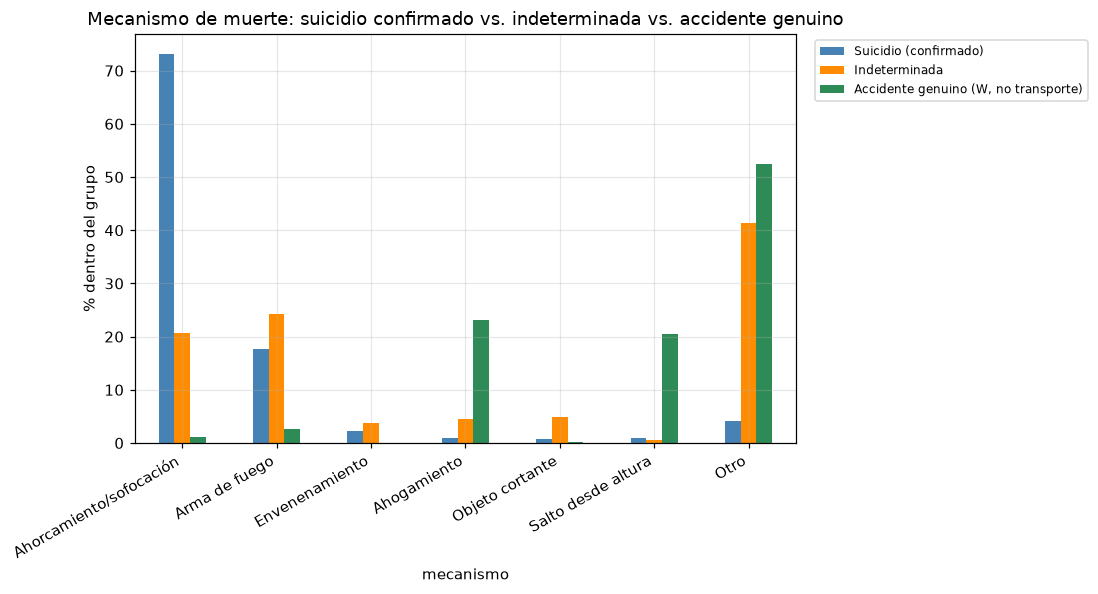

Ahorcamiento + arma de fuego explican 91% del suicidio confirmado, 45% de la intención indeterminada, y sólo 4% de los accidentes genuinos: el mix de métodos de "indeterminada" se parece mucho más al de suicidio que al de un accidente típico.


In [25]:
# --- 12.7.2 Mecanismo de muerte: ¿"indeterminada" se parece a suicidio o a accidente? ---
def mecanismo(code):
    L, n = _cod3(code)
    if L is None: return np.nan
    if (L == 'X' and 60 <= n <= 84) or (L == 'Y' and 10 <= n <= 34):
        if (L == 'X' and 60 <= n <= 69) or (L == 'Y' and 10 <= n <= 19): return 'Envenenamiento'
        if (L == 'X' and n == 70) or (L == 'Y' and n == 20):            return 'Ahorcamiento/sofocación'
        if (L == 'X' and n == 71) or (L == 'Y' and n == 21):            return 'Ahogamiento'
        if (L == 'X' and 72 <= n <= 74) or (L == 'Y' and 22 <= n <= 24): return 'Arma de fuego'
        if (L == 'X' and n == 78) or (L == 'Y' and n == 28):            return 'Objeto cortante'
        if (L == 'X' and n == 80) or (L == 'Y' and n == 30):            return 'Salto desde altura'
        return 'Otro'
    if L == 'W':  # accidentes "genuinos" (excluye transporte V y agresión)
        if n in (75, 76, 77): return 'Ahorcamiento/sofocación'
        if 65 <= n <= 74:     return 'Ahogamiento'
        if 32 <= n <= 34:     return 'Arma de fuego'
        if n in (25, 26):     return 'Objeto cortante'
        if 10 <= n <= 19:     return 'Salto desde altura'
        return 'Otro'
    return np.nan

base['grupo_mec'] = np.select(
    [base['cie10_causa'].str.match(r'^X(6[0-9]|7[0-9]|8[0-4])$', na=False),
     base['cie10_causa'].str.match(r'^Y([1-2][0-9]|3[0-4])$', na=False),
     base['cie10_causa'].str.match(r'^W', na=False)],
    ['Suicidio (confirmado)', 'Indeterminada', 'Accidente genuino (W, no transporte)'], default=None)
base['mecanismo'] = base['cie10_causa'].map(mecanismo)

mec = base[base['grupo_mec'].notna() & base['mecanismo'].notna()]
orden_mec = ['Ahorcamiento/sofocación', 'Arma de fuego', 'Envenenamiento', 'Ahogamiento',
             'Objeto cortante', 'Salto desde altura', 'Otro']
orden_grp = ['Suicidio (confirmado)', 'Indeterminada', 'Accidente genuino (W, no transporte)']

t = (agg(mec, ['grupo_mec', 'mecanismo']).pivot(index='grupo_mec', columns='mecanismo', values='muertes')
     .reindex(index=orden_grp, columns=orden_mec).fillna(0))
pct = (t.div(t.sum(axis=1), axis=0) * 100).round(1)
print('% del mecanismo dentro de cada grupo:')
display(pct)

ax = pct.T.plot.bar(figsize=(10, 5.5), color=['steelblue', 'darkorange', 'seagreen'])
ax.set_ylabel('% dentro del grupo')
ax.set_title('Mecanismo de muerte: suicidio confirmado vs. indeterminada vs. accidente genuino')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); guardar_fig('mecanismo_muerte_suicidio_indeterminada_accidente'); plt.show()

print(f"Ahorcamiento + arma de fuego explican {pct.loc['Suicidio (confirmado)', ['Ahorcamiento/sofocación','Arma de fuego']].sum():.0f}% "
      f"del suicidio confirmado, {pct.loc['Indeterminada', ['Ahorcamiento/sofocación','Arma de fuego']].sum():.0f}% de la "
      f"intención indeterminada, y sólo {pct.loc['Accidente genuino (W, no transporte)', ['Ahorcamiento/sofocación','Arma de fuego']].sum():.0f}% "
      "de los accidentes genuinos: el mix de métodos de \"indeterminada\" se parece mucho más al de suicidio que al de un accidente típico.")


Suicidio confirmado vs. intención indeterminada, acumulado 2005-2024, por región:


,suicidio,indeterminada,ratio
region,,,
CABA,1078,6602,6.12
Buenos Aires,20908,37465,1.79
Centro/Pampeana,13220,12176,0.92
NEA,6448,3332,0.52
Patagonia,4902,1822,0.37
NOA,11329,4205,0.37
Cuyo,5109,1383,0.27


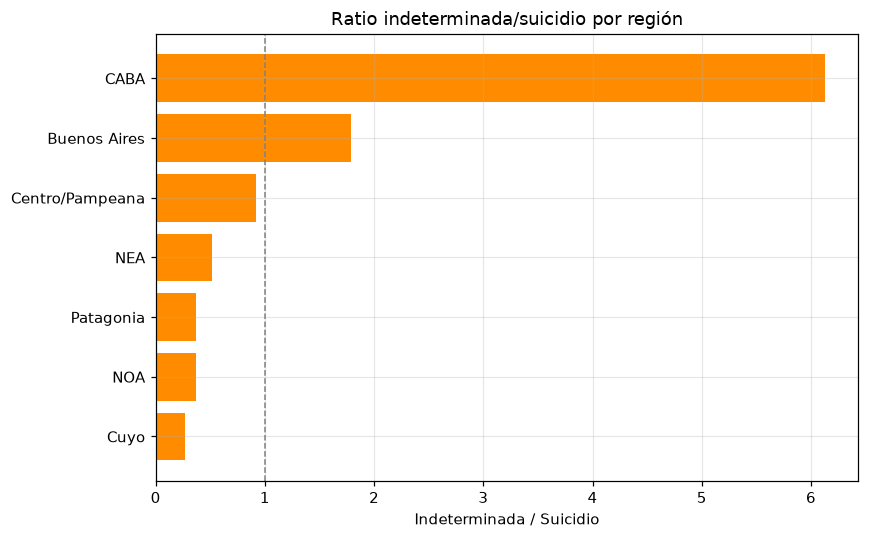

In [26]:
# --- 12.7.3 Patrón geográfico: ¿dónde es mayor el ratio indeterminada/suicidio? ---
suic_reg = agg(base[base['cie10_causa'].str.match(r'^X(6[0-9]|7[0-9]|8[0-4])$', na=False)], ['anio', 'region'])
indet_reg = agg(base[base['cie10_causa'].str.match(r'^Y([1-2][0-9]|3[0-4])$', na=False)], ['anio', 'region'])

reg_cmp = (suic_reg.rename(columns={'muertes': 'suicidio'})
           .merge(indet_reg.rename(columns={'muertes': 'indeterminada'}), on=['anio', 'region'], how='outer')
           .fillna(0))
reg_cmp = reg_cmp[reg_cmp['region'] != 'Sin especificar/Otro']

tab = reg_cmp.groupby('region')[['suicidio', 'indeterminada']].sum()
tab['ratio'] = tab['indeterminada'] / tab['suicidio']
tab = tab.reindex(regiones).sort_values('ratio', ascending=False)
print('Suicidio confirmado vs. intención indeterminada, acumulado 2005-2024, por región:')
display(tab.assign(suicidio=lambda d: d['suicidio'].astype(int), indeterminada=lambda d: d['indeterminada'].astype(int),
                    ratio=lambda d: d['ratio'].round(2)))

plt.figure(figsize=(8, 5))
plt.barh(tab.index[::-1], tab['ratio'][::-1], color='darkorange')
plt.axvline(1, color='gray', ls='--', lw=1)
plt.xlabel('Indeterminada / Suicidio'); plt.title('Ratio indeterminada/suicidio por región')
plt.tight_layout(); guardar_fig('ratio_indeterminada_suicidio_por_region'); plt.show()


**Lectura del ranking regional (chequeá el resultado real, no asumas el signo):** si el ratio resulta más alto en CABA/Buenos Aires que en NOA/Cuyo, es un patrón que **no** encaja con la hipótesis simple de "más estigma social/religioso → más subregistro en provincias más conservadoras". Sería más consistente con diferencias en el **sistema médico-forense y judicial** de cada jurisdicción (capacidad de investigación, criterios de certificación, carga de causas judicializadas) que con estigma cultural puro. Vale la pena tratar este hallazgo como una pregunta abierta para indagar con fuentes cualitativas (protocolos de la Morgue Judicial de PBA, Cuerpo Médico Forense de CABA, etc.), no como una conclusión cerrada.

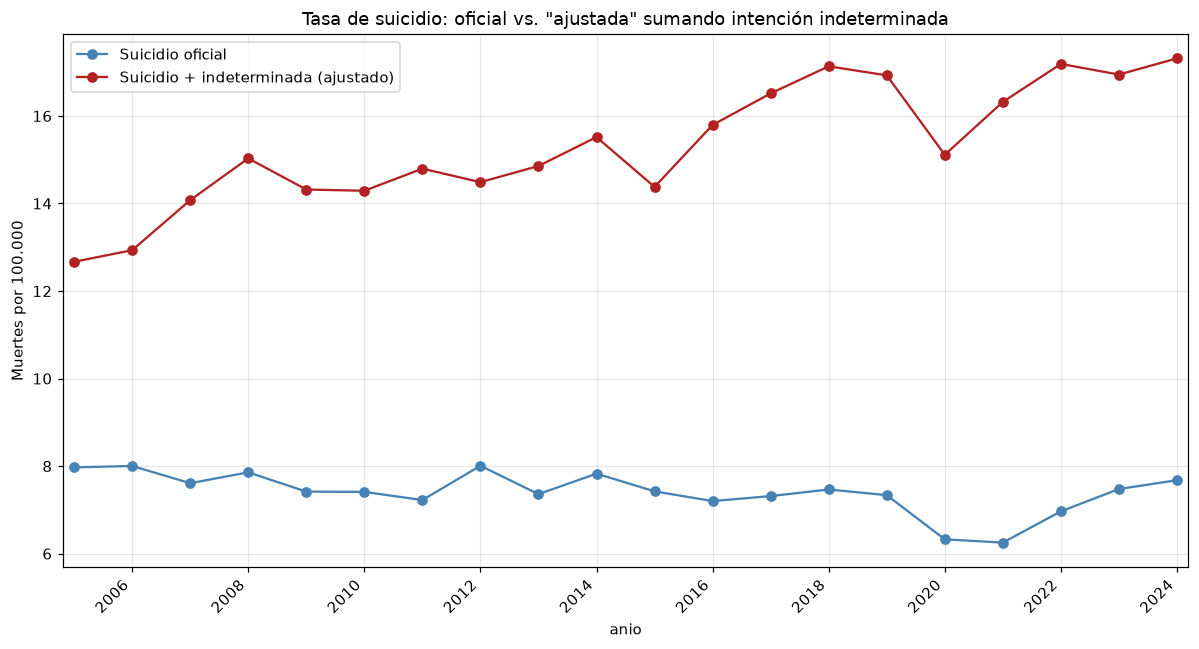

En 2024, la tasa ajustada (17.3/100k) es 2.3x la oficial (7.7/100k).
Esto NO es "la" tasa de suicidio real — es una cota superior plausible, útil para dimensionar cuánto podría estar subestimando la cifra oficial si la hipótesis de subregistro fuera cierta.


In [27]:
# --- 12.7.4 Tasa "ajustada" de suicidio: oficial vs. sumando intención indeterminada ---
tasa_suic = suic_year / pob_nac * 100_000
tasa_indet = indet_year / pob_nac * 100_000
tasa_ajustada = tasa_suic + tasa_indet

cmp_tasa = pd.DataFrame({'Suicidio oficial': tasa_suic, 'Suicidio + indeterminada (ajustado)': tasa_ajustada})
ax = cmp_tasa.plot(marker='o', figsize=(11, 6), color=['steelblue', 'firebrick'])
ax.set_ylabel('Muertes por 100.000')
ax.set_title('Tasa de suicidio: oficial vs. "ajustada" sumando intención indeterminada')
eje_tiempo(ax); plt.tight_layout(); guardar_fig('tasa_suicidio_oficial_vs_ajustada'); plt.show()

print(f"En {tasa_ajustada.index[-1]}, la tasa ajustada ({tasa_ajustada.iloc[-1]:.1f}/100k) es "
      f"{tasa_ajustada.iloc[-1] / tasa_suic.iloc[-1]:.1f}x la oficial ({tasa_suic.iloc[-1]:.1f}/100k).")
print("Esto NO es \"la\" tasa de suicidio real — es una cota superior plausible, útil para dimensionar "
      "cuánto podría estar subestimando la cifra oficial si la hipótesis de subregistro fuera cierta.")


### 12.7.5 Suicidio ajustado por mecanismo (más conservador que sumar todo Y10-Y34)

El ajuste de 12.7.4 suma **toda** la intención indeterminada (Y10-Y34), incluyendo mecanismos que casi no aparecen en suicidio confirmado (ahogamiento, objeto cortante, "otro"). Acá se hace un ajuste más específico, usando la evidencia de 12.7.2: sólo se suma la porción de "indeterminada" cuyo **mecanismo** coincide con los métodos que de hecho dominan el suicidio confirmado.

- **Ajustado**: Suicidio (X60-X84) + Indeterminada por ahorcamiento/sofocación (Y20) — el mecanismo que por sí solo explica ~73% del suicidio confirmado.
- **Ajustado expandido**: lo anterior + Indeterminada por arma de fuego (Y22-Y24) — segundo mecanismo en importancia (~18% del suicidio confirmado).

Sigue sin ser una cifra "real" de suicidio (parte de esa indeterminada por ahorcamiento/arma de fuego puede ser un accidente o una agresión genuinos), pero es una estimación más defendible que sumar el bloque completo de indeterminada.

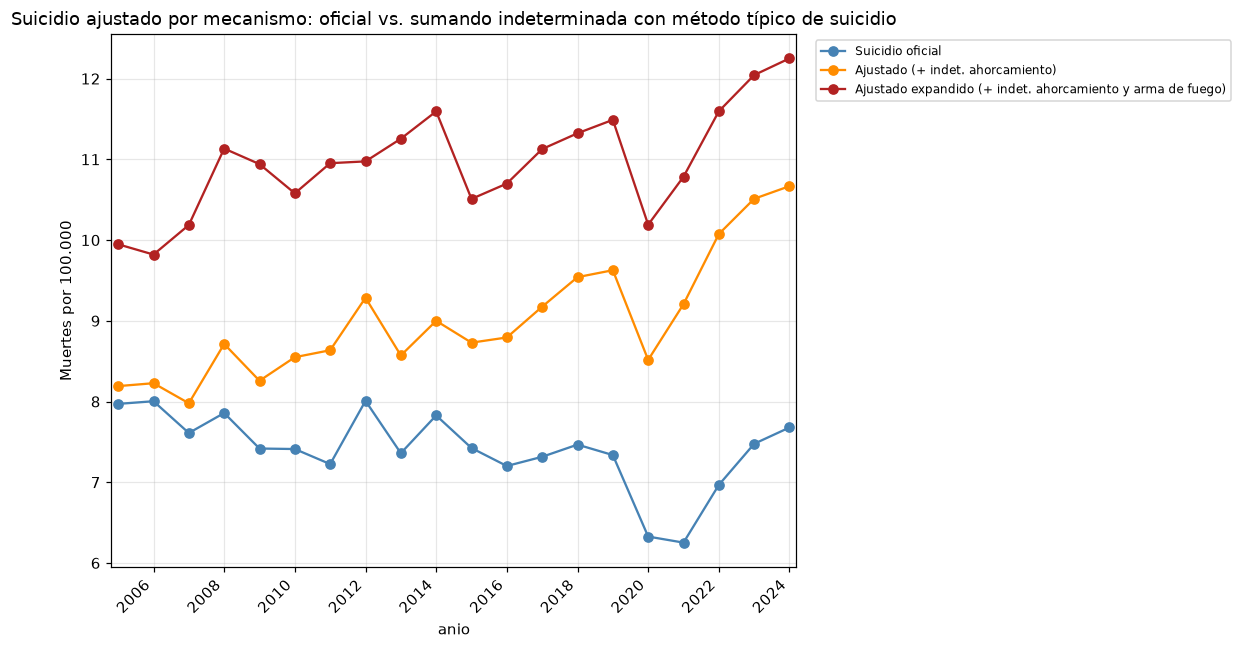

Tasa por 100.000, último año disponible:
Suicidio oficial                                               7.7
Ajustado (+ indet. ahorcamiento)                              10.7
Ajustado expandido (+ indet. ahorcamiento y arma de fuego)    12.3

Ajustado (sólo ahorcamiento): 1.39x la tasa oficial.
Ajustado expandido (+ arma de fuego): 1.60x la tasa oficial (vs. 2.26x si se suma TODA la indeterminada, sección 12.7.4).


In [28]:
indet_ahorc_year = agg(base[(base['grupo_mec'] == 'Indeterminada') & (base['mecanismo'] == 'Ahorcamiento/sofocación')],
                        ['anio']).set_index('anio')['muertes'].reindex(suic_year.index, fill_value=0)
indet_arma_year = agg(base[(base['grupo_mec'] == 'Indeterminada') & (base['mecanismo'] == 'Arma de fuego')],
                       ['anio']).set_index('anio')['muertes'].reindex(suic_year.index, fill_value=0)

suicidio_ajustado = suic_year + indet_ahorc_year
suicidio_ajustado_expandido = suicidio_ajustado + indet_arma_year

conteo_ajust_mec = pd.DataFrame({
    'Suicidio oficial': suic_year,
    'Ajustado (+ indet. ahorcamiento)': suicidio_ajustado,
    'Ajustado expandido (+ indet. ahorcamiento y arma de fuego)': suicidio_ajustado_expandido,
})
tasa_ajust_mec = conteo_ajust_mec.div(pob_nac, axis=0) * 100_000

ax = tasa_ajust_mec.plot(marker='o', figsize=(11, 6), color=['steelblue', 'darkorange', 'firebrick'])
ax.set_ylabel('Muertes por 100.000')
ax.set_title('Suicidio ajustado por mecanismo: oficial vs. sumando indeterminada con método típico de suicidio')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
eje_tiempo(ax); plt.tight_layout(); guardar_fig('tasa_suicidio_ajustada_por_mecanismo'); plt.show()

print('Tasa por 100.000, último año disponible:')
print(tasa_ajust_mec.round(1).iloc[-1].to_string())
print()
u = tasa_ajust_mec.iloc[-1]
print(f"Ajustado (sólo ahorcamiento): {u.iloc[1] / u.iloc[0]:.2f}x la tasa oficial.")
print(f"Ajustado expandido (+ arma de fuego): {u.iloc[2] / u.iloc[0]:.2f}x la tasa oficial "
      f"(vs. {tasa_ajustada.iloc[-1] / tasa_suic.iloc[-1]:.2f}x si se suma TODA la indeterminada, sección 12.7.4).")


### 12.7.6 FS/S ratio: proxy de tenencia de armas por provincia

Cuando no hay una encuesta directa de tenencia de armas, la literatura de EE.UU. (Siegel, Ross & King, 2013) usa el **FS/S ratio**: la fracción de suicidios cometidos con arma de fuego sobre el total de suicidios de esa jurisdicción, como proxy de cuánta disponibilidad de armas hay en la población general. La lógica: si dos lugares tienen tasas de suicidio parecidas pero en uno la mitad se hace con arma de fuego y en el otro casi nada, es señal de que en el primero es más fácil acceder a una.

**Ojo con la circularidad**: el mecanismo (`X72-X74`) es parte de la misma variable que estamos tratando de explicar en el resto de la sección 12 (el índice "despair" y el ajuste por indeterminada). Por eso este ratio sirve para una **primera mirada descriptiva** de la geografía de armas, no como instrumento causal — para eso hace falta un dato de tenencia real e independiente (RENAR/ANMaC).

FS/S ratio (proxy de tenencia de armas) por provincia, acumulado 2005-2024:


,suicidios_total,suicidios_arma,FS/S (%)
provincia,,,
La Pampa,839,290,34.6
Ciudad Autónoma de Buenos Aires,1078,240,22.3
Buenos Aires,20908,4367,20.9
San Luis,895,185,20.7
Córdoba,4171,862,20.7
Santa Fe,5036,974,19.3
Entre Ríos,3174,598,18.8
Chaco,1552,292,18.8
Chubut,1144,214,18.7


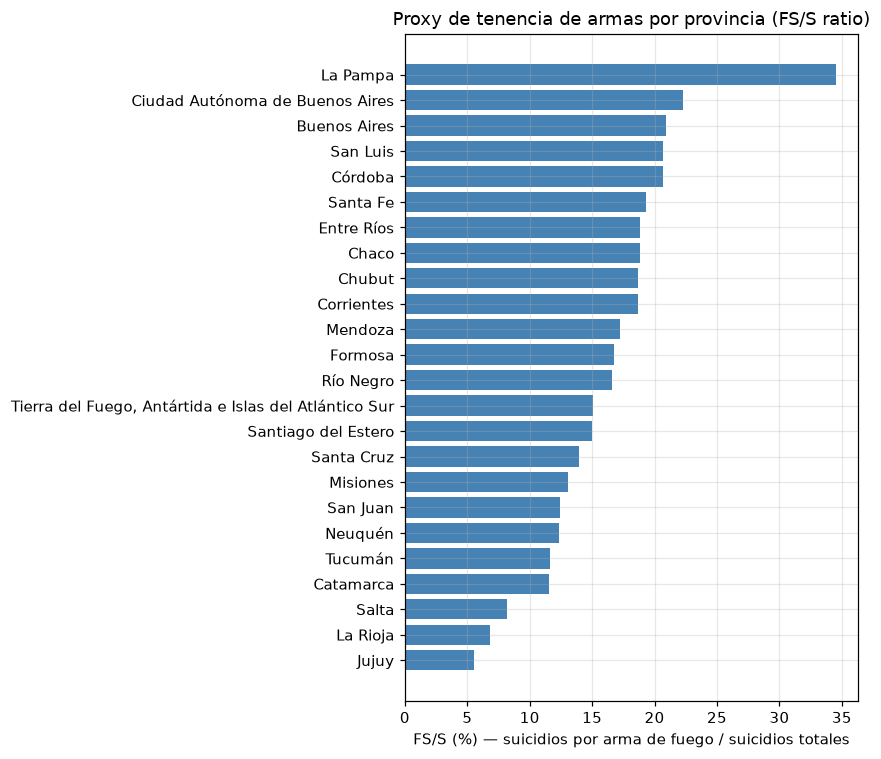

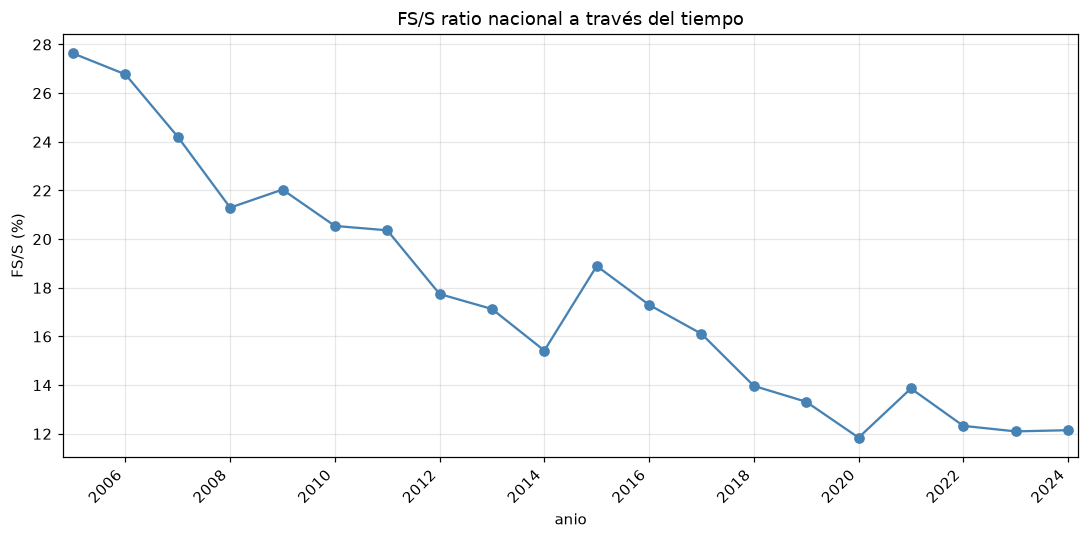

Rango entre provincias: 5.6% - 34.6%. Si esta dispersión no encaja con lo que uno esperaría por densidad urbana o tradición rural/de caza, puede ser señal de que el ratio está capturando algo del sistema de certificación (sección 12.7.3) más que disponibilidad real de armas — usarlo junto con RENAR/ANMaC apenas esté disponible.


In [29]:
# jurisdiccion_nombre viene con problemas de encoding en el CSV fuente; reconstruimos el nombre
# limpio a partir de jurisdiccion_id con el mismo NAME2ID (INDEC) que ya usamos para población.
ID2NAME = {v: k for k, v in NAME2ID.items()}
base['provincia'] = base['jurisdiccion_id'].map(ID2NAME)

es_suicidio = base['cie10_causa'].str.match(r'^X(6[0-9]|7[0-9]|8[0-4])$', na=False)
es_suicidio_arma = base['cie10_causa'].str.match(r'^X7[2-4]$', na=False)

fss_prov = (base[es_suicidio].groupby('provincia')['cantidad'].sum().rename('suicidios_total').to_frame()
            .join(base[es_suicidio_arma].groupby('provincia')['cantidad'].sum().rename('suicidios_arma')))
fss_prov['FS_S'] = 100 * fss_prov['suicidios_arma'] / fss_prov['suicidios_total']
fss_prov = fss_prov[fss_prov['suicidios_total'] >= 100].sort_values('FS_S', ascending=False)  # evita ratios ruidosos en jurisdicciones chicas

print('FS/S ratio (proxy de tenencia de armas) por provincia, acumulado 2005-2024:')
display(fss_prov.assign(suicidios_total=lambda d: d['suicidios_total'].astype(int),
                         suicidios_arma=lambda d: d['suicidios_arma'].astype(int),
                         FS_S=lambda d: d['FS_S'].round(1)).rename(columns={'FS_S': 'FS/S (%)'}))

plt.figure(figsize=(8, 7))
plt.barh(fss_prov.index[::-1], fss_prov['FS_S'][::-1], color='steelblue')
plt.xlabel('FS/S (%) — suicidios por arma de fuego / suicidios totales')
plt.title('Proxy de tenencia de armas por provincia (FS/S ratio)')
plt.tight_layout(); guardar_fig('fss_ratio_por_provincia'); plt.show()

# --- Tendencia nacional del FS/S en el tiempo ---
fss_year = (agg(base[es_suicidio], ['anio']).rename(columns={'muertes': 'total'})
            .merge(agg(base[es_suicidio_arma], ['anio']).rename(columns={'muertes': 'arma'}), on='anio'))
fss_year['FS_S'] = 100 * fss_year['arma'] / fss_year['total']
ax = fss_year.set_index('anio')['FS_S'].plot(marker='o', figsize=(10, 5), color='steelblue')
ax.set_ylabel('FS/S (%)'); ax.set_title('FS/S ratio nacional a través del tiempo')
eje_tiempo(ax); plt.tight_layout(); guardar_fig('fss_ratio_nacional_tiempo'); plt.show()

print(f"Rango entre provincias: {fss_prov['FS_S'].min():.1f}% - {fss_prov['FS_S'].max():.1f}%. "
      "Si esta dispersión no encaja con lo que uno esperaría por densidad urbana o tradición rural/de caza, "
      "puede ser señal de que el ratio está capturando algo del sistema de certificación (sección 12.7.3) "
      "más que disponibilidad real de armas — usarlo junto con RENAR/ANMaC apenas esté disponible.")


### 12.7.7 Muertes por arma de fuego por provincia, según intención

Histograma de barras apiladas: **tasa** de muertes por arma de fuego por provincia (por 100.000 habitantes, promedio anual 2005-2024 usando personas-año como denominador, igual que en 12.7.4-12.7.6), desglosada en **homicidio** (`X93-X95`), **suicidio** (`X72-X74`) e **intención indeterminada** (`Y22-Y24`). Usar tasas en vez de conteos absolutos es lo que hace comparables a provincias de población muy distinta (p.ej. CABA vs. Formosa).

Años incluidos: [np.int64(2022), np.int64(2023), np.int64(2024)]


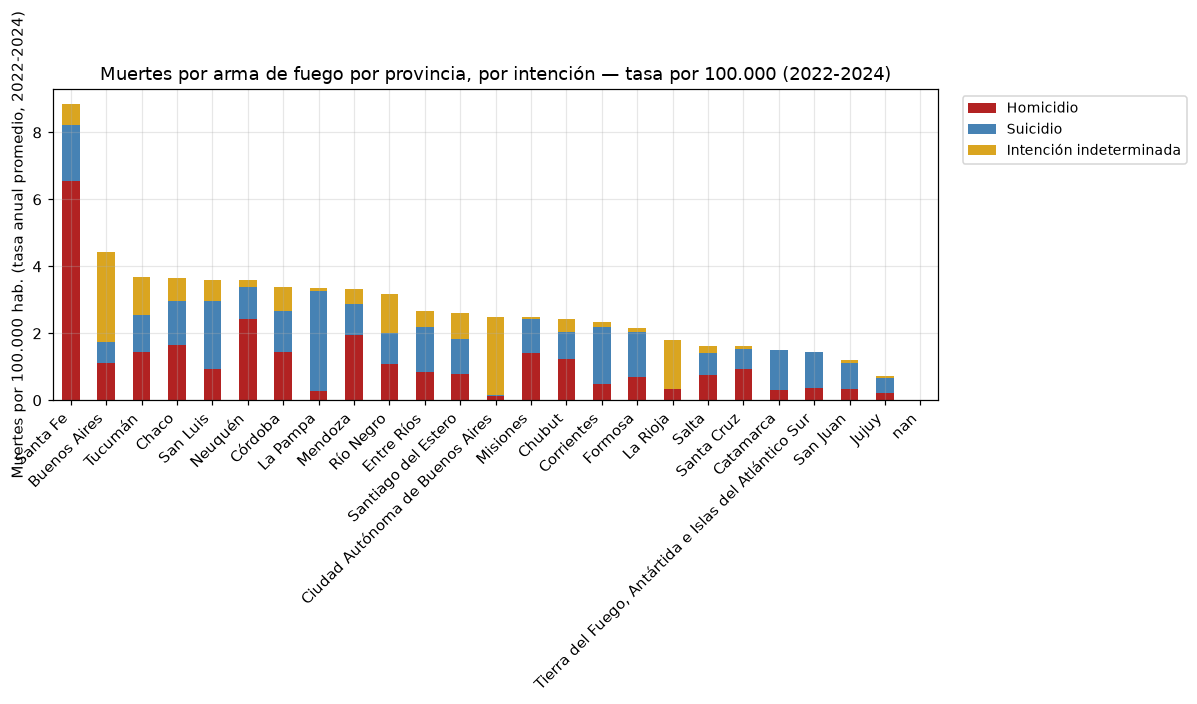

Tasa por 100.000 hab. (promedio anual, 2022-2024):


tipo_arma,Homicidio,Suicidio,Intención indeterminada,Total
provincia,,,,
Santa Fe,6.56,1.65,0.64,8.85
Buenos Aires,1.12,0.63,2.67,4.42
Tucumán,1.44,1.10,1.12,3.67
Chaco,1.64,1.32,0.70,3.66
San Luis,0.95,2.02,0.63,3.61
Neuquén,2.42,0.97,0.19,3.58
Córdoba,1.43,1.25,0.70,3.37
La Pampa,0.27,3.00,0.09,3.36
Mendoza,1.94,0.93,0.46,3.32


In [30]:
# --- 12.7.7 Muertes por arma de fuego por provincia, según intención (tasa por 100.000, últimos 3 años) ---
N_ANIOS = 3
anios_arma = sorted(base['anio'].dropna().unique())[-N_ANIOS:]
print(f'Años incluidos: {anios_arma}')

es_homicidio_arma = base['cie10_causa'].str.match(r'^X9[3-5]$', na=False)
es_suicidio_arma_  = base['cie10_causa'].str.match(r'^X7[2-4]$', na=False)
es_indet_arma      = base['cie10_causa'].str.match(r'^Y2[2-4]$', na=False)

base['tipo_arma'] = np.select(
    [es_homicidio_arma, es_suicidio_arma_, es_indet_arma],
    ['Homicidio', 'Suicidio', 'Intención indeterminada'],
    default=None)

arma = base[base['tipo_arma'].notna() & base['anio'].isin(anios_arma)]
conteo_prov_arma = (agg(arma, ['provincia', 'tipo_arma'])
                     .pivot(index='provincia', columns='tipo_arma', values='muertes')
                     .reindex(columns=['Homicidio', 'Suicidio', 'Intención indeterminada'])
                     .fillna(0))

# Personas-año de los mismos años, por provincia (denominador de la tasa)
persona_anios = pob_tot[pob_tot['anio'].isin(anios_arma)].groupby('jurisdiccion_id')['ambos'].sum()
persona_anios.index = persona_anios.index.map(ID2NAME)
persona_anios = persona_anios.rename('persona_anios')

tasa_prov_arma = conteo_prov_arma.div(persona_anios, axis=0) * 100_000
tasa_prov_arma = tasa_prov_arma.loc[tasa_prov_arma.sum(axis=1).sort_values(ascending=False).index]

ax = tasa_prov_arma.plot.bar(stacked=True, figsize=(11, 6),
                              color=['firebrick', 'steelblue', 'goldenrod'])
ax.set_ylabel(f'Muertes por 100.000 hab. (tasa anual promedio, {anios_arma[0]}-{anios_arma[-1]})')
ax.set_xlabel('')
ax.set_title(f'Muertes por arma de fuego por provincia, por intención — tasa por 100.000 ({anios_arma[0]}-{anios_arma[-1]})')
ax.legend(title='', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.xticks(rotation=45, ha='right')
plt.tight_layout(); guardar_fig(f'muertes_arma_fuego_por_provincia_tasa_100k_{anios_arma[0]}_{anios_arma[-1]}'); plt.show()

print(f'Tasa por 100.000 hab. (promedio anual, {anios_arma[0]}-{anios_arma[-1]}):')
display(tasa_prov_arma.assign(Total=tasa_prov_arma.sum(axis=1)).round(2))

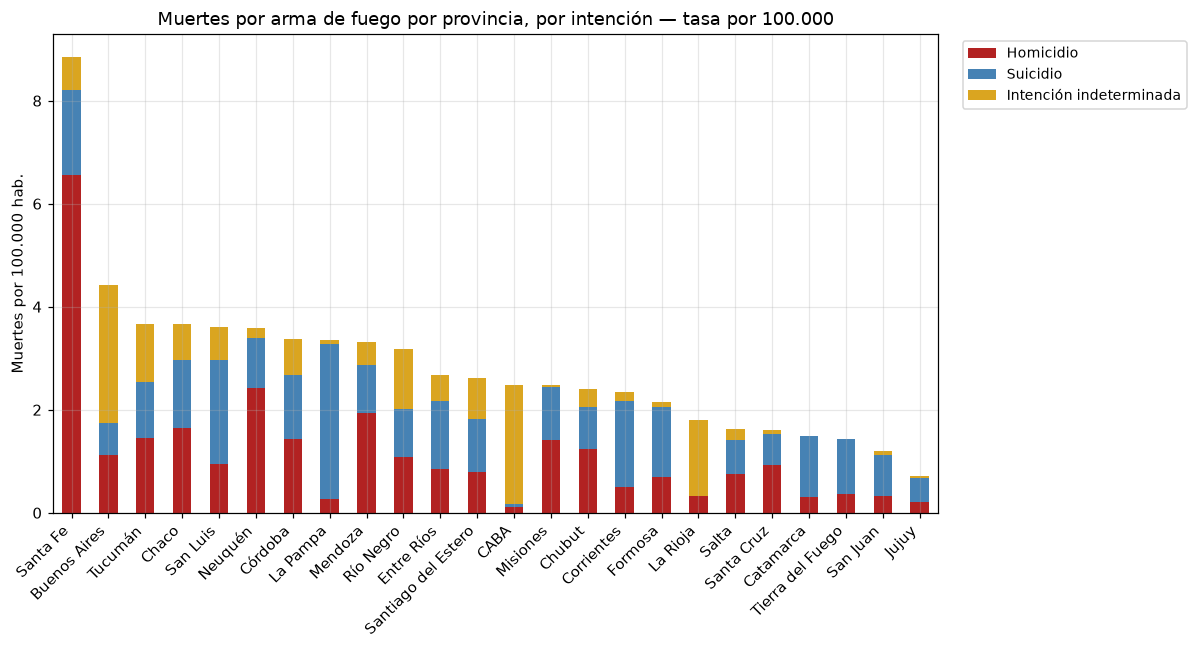

In [31]:
# --- 12.7.7b Etiquetas cortas y sin fila NaN ---
RENOMBRAR_PROV = {
    'Tierra del Fuego, Antártida e Islas del Atlántico Sur': 'Tierra del Fuego',
    'Ciudad Autónoma de Buenos Aires': 'CABA',
}

tasa_prov_arma_plot = tasa_prov_arma[tasa_prov_arma.index.notna()].rename(index=RENOMBRAR_PROV)

ax = tasa_prov_arma_plot.plot.bar(stacked=True, figsize=(11, 6),
                                   color=['firebrick', 'steelblue', 'goldenrod'])
ax.set_ylabel('Muertes por 100.000 hab.')
ax.set_xlabel('')
ax.set_title('Muertes por arma de fuego por provincia, por intención — tasa por 100.000')
ax.legend(title='', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.xticks(rotation=45, ha='right')
plt.tight_layout(); guardar_fig('muertes_arma_fuego_por_provincia_tasa_100k'); plt.show()

### 12.8 Limitaciones y notas finales de esta sección

- **Granularidad CIE-10 (3 caracteres)**: no se puede aislar alcohol dentro de G31 (degeneración nerviosa), I42 (miocardiopatía) o K85/K86 (pancreatitis) → el bloque "Alcohol" acá es un **piso**, no el total real.
- El mix de mecanismos y el ranking regional son **señales agregadas y correlacionales**, no una auditoría caso por caso. En particular, si el patrón geográfico no encaja con "más estigma → más subregistro en provincias conservadoras", no lo fuerces a esa narrativa: puede reflejar diferencias de capacidad/practica médico-forense entre jurisdicciones, que requieren evidencia cualitativa adicional.
- No hay tasas estandarizadas por edad; con la estructura etaria de Argentina cambiando en el tiempo y siendo distinta entre regiones, comparar tasas crudas entre regiones/años subestima o sobreestima según el envejecimiento relativo de cada una (ver sección 11, punto 2).
- Igual que en la sección 11: chequeá la cobertura de CABA (sección 10) antes de usar sus tasas acá — un salto artificial en la tasa de CABA contamina cualquier lectura de "mejora" o "empeoramiento" regional.
- La categoría "Sobredosis (no suicida)" es chica en este dataset comparada con la literatura de EE.UU. — consistente con que Argentina no tiene (todavía) una epidemia de opioides recetados a esa escala; no extrapoles el marco de EE.UU. 1:1 sin chequear ese supuesto.

**Marco conceptual (lectura adicional, no específica de Argentina):**
- Case, A. & Deaton, A. (2015). *Rising morbidity and mortality in midlife among white non-Hispanic Americans in the 21st century*. PNAS.
- Case, A. & Deaton, A. (2020). *Deaths of Despair and the Future of Capitalism*. Princeton University Press.
- Ruhm, C. y otros autores discuten si "desesperanza" es la explicación correcta o si pesa más la disponibilidad de opioides/sustancias — debate abierto, no zanjado acá.
- Rockett, I.R.H. et al., sobre clasificación errónea de intención y "muertes equívocas" (*hidden suicides*/*equivocal deaths*) en estadísticas vitales.
- OMS, recomendaciones sobre calidad del dato de mortalidad por suicidio y el uso de "intención indeterminada" como indicador de calidad de certificación.

## 13. Mapa de suicidio 2024: oficial vs. "corregida" (+ indeterminada ahorcamiento/arma), con varianza entre provincias

Mismo ajuste por mecanismo que 12.7.5 (Suicidio X60-X84 + Indeterminada por ahorcamiento Y20 + Indeterminada por arma de fuego Y22-Y24), pero por provincia y solo para 2024 (año más reciente), en dos mapas coropléticos con la misma escala de color. Además de los mapas, se calcula la **varianza entre provincias** (N=24) de cada tasa: compara qué tan dispersa está la tasa oficial entre provincias contra qué tan dispersa queda la corregida — si la corrección achica la varianza, sugiere que "indeterminada" está rellenando más donde el oficial estaba más bajo (parte de la heterogeneidad oficial sería un artefacto de clasificación).


In [32]:
# --- 13.1 Geometría provincial ---
# Departamentos INDEC (censo) disueltos a nivel provincia. Shapefile de otro proyecto propio
# (Health project/Data/Raw/Codgeo_Pais_x_dpto_con_datos), 'codpcia' usa el mismo estándar INDEC
# que 'jurisdiccion_id' acá (mismos códigos que NAME2ID).
import geopandas as gpd

SHP_PATH = "data/geo/pxdptodatosok.shp"
dptos = gpd.read_file(SHP_PATH)

# Excluye el departamento "Antártida Argentina" (reclamo antártico, geometría hasta -90° lat):
# si se lo incluye, el mapa queda dominado por un polígono fuera de la escala continental.
dptos_cont = dptos[~dptos['departamen'].str.contains('Antártida', case=False, na=False)].copy()

# 'Islas del Atlántico Sur' (depto de Tierra del Fuego) junta en un solo MultiPolygon las
# Malvinas (cerca del continente) con Georgias del Sur y Sandwich del Sur (~1500-2000 km al
# este): esas dos últimas estiran el bounding box del mapa y achican el continente en el plot.
# Nos quedamos solo con las sub-geometrías al oeste de -45° de longitud (Malvinas incluidas,
# Georgias/Sandwich excluidas).
from shapely.geometry import MultiPolygon

mask_islas = dptos_cont['departamen'].str.contains('Atlántico Sur', case=False, na=False)
idx_islas = dptos_cont[mask_islas].index[0]
geom_islas = dptos_cont.loc[idx_islas, 'geometry']
geom_islas_recortado = MultiPolygon([g for g in geom_islas.geoms if g.bounds[2] < -45])
dptos_cont.loc[idx_islas, 'geometry'] = geom_islas_recortado


geo_prov = dptos_cont.dissolve(by='codpcia').reset_index()
geo_prov['jurisdiccion_id'] = geo_prov['codpcia'].astype(int)

# Proyección cónica equivalente centrada en Argentina (mejor que lat/lon crudo para un mapa impreso)
AEA_ARG = "+proj=aea +lat_1=-30 +lat_2=-50 +lat_0=-40 +lon_0=-64 +datum=WGS84 +units=m +no_defs"
geo_prov = geo_prov.to_crs(AEA_ARG)

print(f'{len(geo_prov)} provincias en la geometría (esperado: 24)')
assert set(geo_prov['jurisdiccion_id']) == set(NAME2ID.values()), 'IDs de geometría no calzan con NAME2ID'


24 provincias en la geometría (esperado: 24)


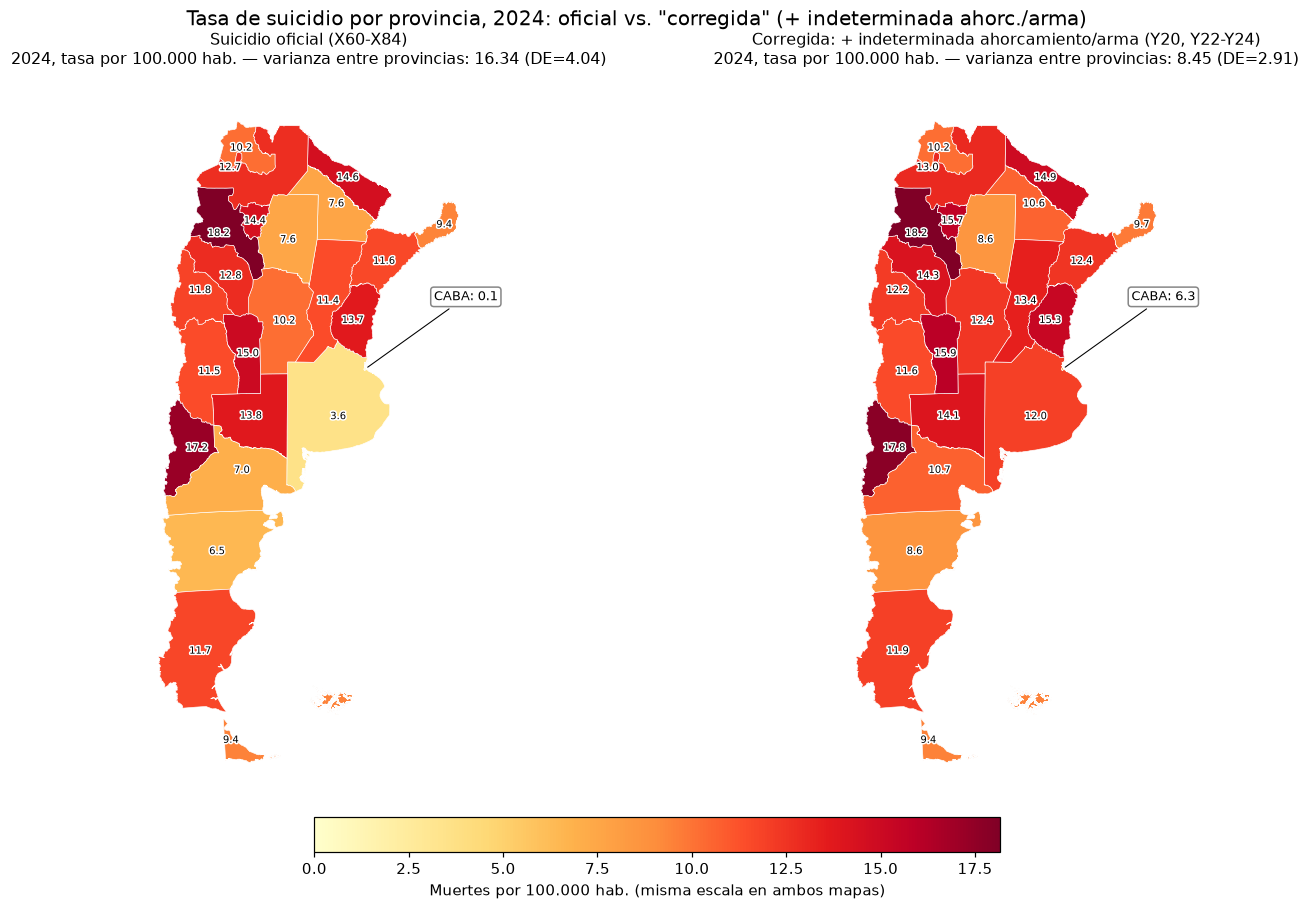

,provincia,Oficial,Corregida (+ indet. ahorc./arma),Diferencia
0,Buenos Aires,3.60,11.97,8.36
1,Ciudad Autónoma de Buenos Aires,0.13,6.26,6.13
2,Río Negro,7.01,10.70,3.70
3,Chaco,7.60,10.64,3.04
4,Córdoba,10.18,12.38,2.20
5,Chubut,6.52,8.65,2.12
6,Santa Fe,11.45,13.37,1.92
7,Entre Ríos,13.73,15.33,1.60
8,La Rioja,12.81,14.26,1.45
9,Tucumán,14.38,15.74,1.35



Varianza entre provincias (N=24), 2024: oficial=16.34 (DE=4.04) -> corregida=8.45 (DE=2.91), -48.3%.
Si la varianza BAJA al corregir, la heterogeneidad entre provincias en el mapa oficial es en parte un artefacto de clasificación (la indeterminada 'rellena' más donde el oficial estaba más bajo, achicando la brecha real). Si SUBE, la corrección amplifica diferencias entre provincias en vez de achicarlas.


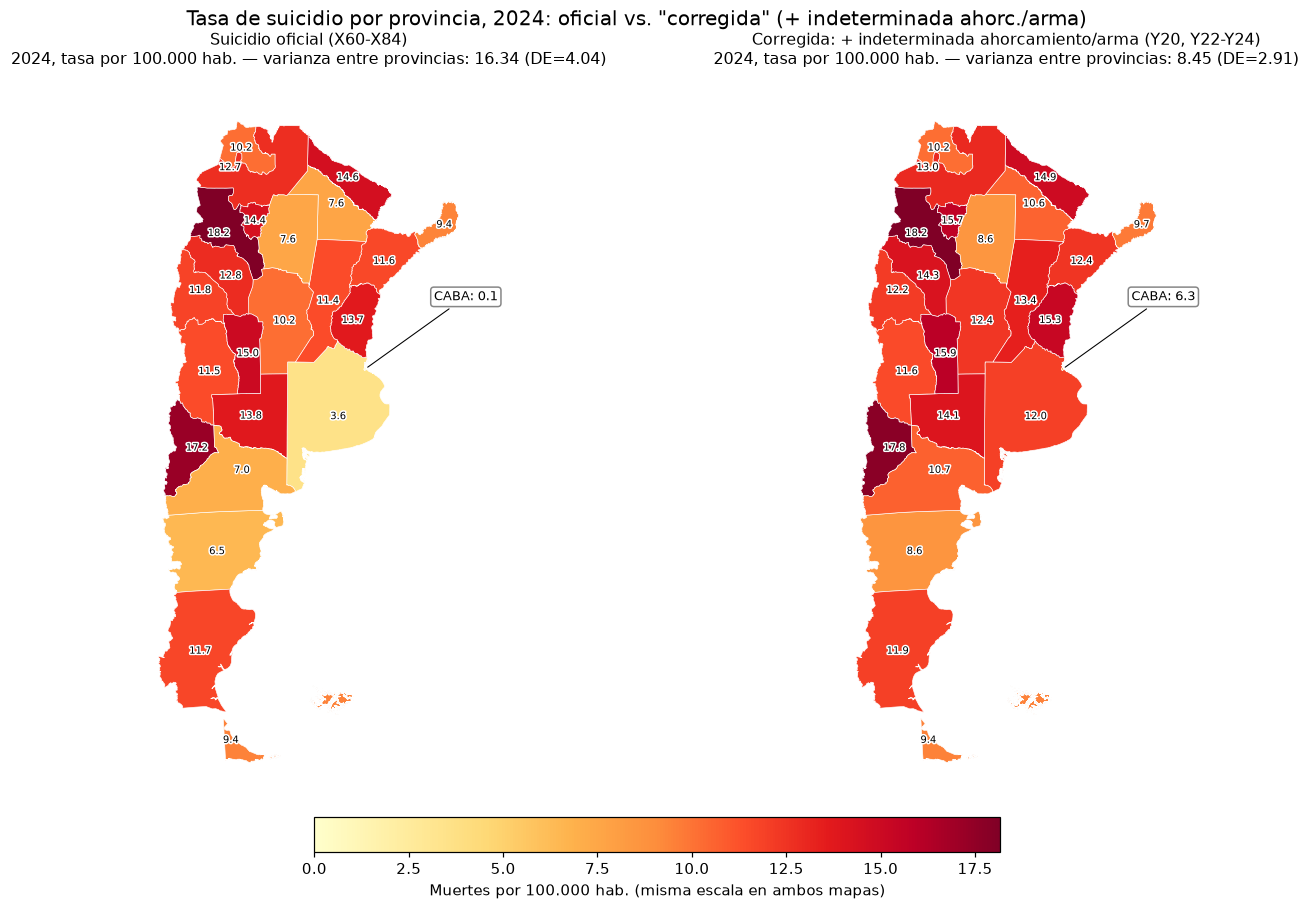

,provincia,Oficial,Corregida (+ indet. ahorc./arma),Diferencia
0,Buenos Aires,3.60,11.97,8.36
1,Ciudad Autónoma de Buenos Aires,0.13,6.26,6.13
2,Río Negro,7.01,10.70,3.70
3,Chaco,7.60,10.64,3.04
4,Córdoba,10.18,12.38,2.20
5,Chubut,6.52,8.65,2.12
6,Santa Fe,11.45,13.37,1.92
7,Entre Ríos,13.73,15.33,1.60
8,La Rioja,12.81,14.26,1.45
9,Tucumán,14.38,15.74,1.35



Varianza entre provincias (N=24), 2024: oficial=16.34 (DE=4.04) -> corregida=8.45 (DE=2.91), -48.3%.
Si la varianza BAJA al corregir, la heterogeneidad entre provincias en el mapa oficial es en parte un artefacto de clasificación (la indeterminada 'rellena' más donde el oficial estaba más bajo, achicando la brecha real). Si SUBE, la corrección amplifica diferencias entre provincias en vez de achicarlas.


In [33]:
# --- 13.2 Tasa de suicidio 2024: oficial vs. corregida (+ indet. ahorc./arma), por provincia ---
# --- 13.2 Tasa de suicidio 2024: oficial vs. corregida (+ indet. ahorc./arma), por provincia ---
ANIO_UNICO = 2024

es_suicidio_sc = base['cie10_causa'].str.match(r'^X(6[0-9]|7[0-9]|8[0-4])$', na=False)
es_indet_ahorc_arma = base['cie10_causa'].str.match(r'^Y(20|2[2-4])$', na=False)
base['tipo_sc'] = np.select([es_suicidio_sc, es_indet_ahorc_arma],
                                          ['Suicidio', 'Indeterminada (ahorc./arma)'], default=None)
ORDEN_SC = ['Suicidio', 'Indeterminada (ahorc./arma)']

win_2024 = base[base['tipo_sc'].notna() & (base['anio'] == ANIO_UNICO)]

persona_2024 = pob_tot.loc[pob_tot['anio'] == ANIO_UNICO].groupby('jurisdiccion_id')['ambos'].sum()

conteo_2024 = (agg(win_2024, ['jurisdiccion_id', 'tipo_sc'])
                     .pivot(index='jurisdiccion_id', columns='tipo_sc', values='muertes')
                     .reindex(columns=ORDEN_SC).fillna(0))

tasa_2024 = conteo_2024.div(persona_2024, axis=0) * 100_000
tasa_2024['Oficial'] = tasa_2024['Suicidio']
tasa_2024['Corregida (+ indet. ahorc./arma)'] = tasa_2024['Suicidio'] + tasa_2024['Indeterminada (ahorc./arma)']

mapa_2024 = geo_prov.merge(tasa_2024[['Oficial', 'Corregida (+ indet. ahorc./arma)']],
                                          left_on='jurisdiccion_id', right_index=True, how='left')

# Fallback para asegurar que exista la columna 'provincia' en el mapa
if 'provincia' not in mapa_2024.columns:
      prov_names = base.drop_duplicates('jurisdiccion_id').set_index('jurisdiccion_id')['jurisdiccion_nombre']
      mapa_2024['provincia'] = mapa_2024['jurisdiccion_id'].map(prov_names)

# Varianza (entre provincias, N=24) de la tasa oficial vs. la corregida
var_oficial = mapa_2024['Oficial'].var(ddof=0)
sd_oficial = mapa_2024['Oficial'].std(ddof=0)
var_corr = mapa_2024['Corregida (+ indet. ahorc./arma)'].var(ddof=0)
sd_corr = mapa_2024['Corregida (+ indet. ahorc./arma)'].std(ddof=0)
var_por_col = {'Oficial': (var_oficial, sd_oficial),
                     'Corregida (+ indet. ahorc./arma)': (var_corr, sd_corr)}

vmin, vmax = 0, mapa_2024['Corregida (+ indet. ahorc./arma)'].max()

import matplotlib.patheffects as pe

fig, axes = plt.subplots(1, 2, figsize=(15, 9))
paneles = [('Oficial', 'Suicidio oficial (X60-X84)'),
               ('Corregida (+ indet. ahorc./arma)', 'Corregida: + indeterminada ahorcamiento/arma (Y20, Y22-Y24)')]
for ax, (col, titulo) in zip(axes, paneles):
      mapa_2024.plot(column=col, cmap='YlOrRd', vmin=vmin, vmax=vmax, ax=ax,
                           edgecolor='white', linewidth=0.4, legend=False)
      v, s = var_por_col[col]
      ax.set_title(f'{titulo}\n{ANIO_UNICO}, tasa por 100.000 hab. — varianza entre provincias: {v:.2f} (DE={s:.2f})',
                         fontsize=10.5)
      ax.axis('off')
      caba = mapa_2024[mapa_2024['jurisdiccion_id'] == 2]
      cx, cy = caba.geometry.centroid.iloc[0].coords[0]
      val = caba[col].iloc[0]
      ax.annotate(f'CABA: {val:.1f}', xy=(cx, cy), xytext=(45, 45), textcoords='offset points',
                        fontsize=8.5, ha='left',
                        arrowprops=dict(arrowstyle='-', color='black', lw=0.7),
                        bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='gray', alpha=0.95))

      # Etiqueta numérica en cada provincia (evita ambigüedad de leer el color a ojo
      # entre dos provincias no vecinas con tonos parecidos)
      for _, r in mapa_2024[mapa_2024['jurisdiccion_id'] != 2].iterrows():
            rp = r.geometry.representative_point()
            ax.annotate(f'{r[col]:.1f}', xy=(rp.x, rp.y), ha='center', va='center',
                              fontsize=6.5, color='black',
                              path_effects=[pe.withStroke(linewidth=2, foreground='white')])

sm = plt.cm.ScalarMappable(cmap='YlOrRd', norm=plt.Normalize(vmin=vmin, vmax=vmax))
cbar = fig.colorbar(sm, ax=axes, orientation='horizontal', fraction=0.045, pad=0.03, shrink=0.55)
cbar.set_label('Muertes por 100.000 hab. (misma escala en ambos mapas)')

fig.suptitle(f'Tasa de suicidio por provincia, {ANIO_UNICO}: oficial vs. "corregida" (+ indeterminada ahorc./arma)',
                   fontsize=13, y=0.96)
guardar_fig('mapa_suicidio_oficial_vs_corregida_por_provincia_2024', fig)
plt.show()

display(mapa_2024[['provincia', 'Oficial', 'Corregida (+ indet. ahorc./arma)']]
            .assign(Diferencia=lambda d: (d['Corregida (+ indet. ahorc./arma)'] - d['Oficial']))
            .round(2).sort_values('Diferencia', ascending=False).reset_index(drop=True))

cambio_var_pct = 100 * (var_corr - var_oficial) / var_oficial
print(f"\nVarianza entre provincias (N=24), {ANIO_UNICO}: oficial={var_oficial:.2f} (DE={sd_oficial:.2f}) "
        f"-> corregida={var_corr:.2f} (DE={sd_corr:.2f}), {cambio_var_pct:+.1f}%.")
print("Si la varianza BAJA al corregir, la heterogeneidad entre provincias en el mapa oficial es en parte "
        "un artefacto de clasificación (la indeterminada 'rellena' más donde el oficial estaba más bajo, "
        "achicando la brecha real). Si SUBE, la corrección amplifica diferencias entre provincias en vez "
        "de achicarlas.")

es_suicidio_sc = base['cie10_causa'].str.match(r'^X(6[0-9]|7[0-9]|8[0-4])$', na=False)
es_indet_ahorc_arma = base['cie10_causa'].str.match(r'^Y(20|2[2-4])$', na=False)
base['tipo_sc'] = np.select([es_suicidio_sc, es_indet_ahorc_arma],
                             ['Suicidio', 'Indeterminada (ahorc./arma)'], default=None)
ORDEN_SC = ['Suicidio', 'Indeterminada (ahorc./arma)']

win_2024 = base[base['tipo_sc'].notna() & (base['anio'] == ANIO_UNICO)]

persona_2024 = pob_tot.loc[pob_tot['anio'] == ANIO_UNICO].groupby('jurisdiccion_id')['ambos'].sum()

conteo_2024 = (agg(win_2024, ['jurisdiccion_id', 'tipo_sc'])
               .pivot(index='jurisdiccion_id', columns='tipo_sc', values='muertes')
               .reindex(columns=ORDEN_SC).fillna(0))

tasa_2024 = conteo_2024.div(persona_2024, axis=0) * 100_000
tasa_2024['Oficial'] = tasa_2024['Suicidio']
tasa_2024['Corregida (+ indet. ahorc./arma)'] = tasa_2024['Suicidio'] + tasa_2024['Indeterminada (ahorc./arma)']

mapa_2024 = geo_prov.merge(tasa_2024[['Oficial', 'Corregida (+ indet. ahorc./arma)']],
                            left_on='jurisdiccion_id', right_index=True, how='left')

# Varianza (entre provincias, N=24) de la tasa oficial vs. la corregida
var_oficial = mapa_2024['Oficial'].var(ddof=0)
sd_oficial = mapa_2024['Oficial'].std(ddof=0)
var_corr = mapa_2024['Corregida (+ indet. ahorc./arma)'].var(ddof=0)
sd_corr = mapa_2024['Corregida (+ indet. ahorc./arma)'].std(ddof=0)
var_por_col = {'Oficial': (var_oficial, sd_oficial),
               'Corregida (+ indet. ahorc./arma)': (var_corr, sd_corr)}

vmin, vmax = 0, mapa_2024['Corregida (+ indet. ahorc./arma)'].max()

import matplotlib.patheffects as pe

fig, axes = plt.subplots(1, 2, figsize=(15, 9))
paneles = [('Oficial', 'Suicidio oficial (X60-X84)'),
           ('Corregida (+ indet. ahorc./arma)', 'Corregida: + indeterminada ahorcamiento/arma (Y20, Y22-Y24)')]
for ax, (col, titulo) in zip(axes, paneles):
    mapa_2024.plot(column=col, cmap='YlOrRd', vmin=vmin, vmax=vmax, ax=ax,
                    edgecolor='white', linewidth=0.4, legend=False)
    v, s = var_por_col[col]
    ax.set_title(f'{titulo}\n{ANIO_UNICO}, tasa por 100.000 hab. — varianza entre provincias: {v:.2f} (DE={s:.2f})',
                 fontsize=10.5)
    ax.axis('off')
    caba = mapa_2024[mapa_2024['jurisdiccion_id'] == 2]
    cx, cy = caba.geometry.centroid.iloc[0].coords[0]
    val = caba[col].iloc[0]
    ax.annotate(f'CABA: {val:.1f}', xy=(cx, cy), xytext=(45, 45), textcoords='offset points',
                fontsize=8.5, ha='left',
                arrowprops=dict(arrowstyle='-', color='black', lw=0.7),
                bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='gray', alpha=0.95))

    # Etiqueta numérica en cada provincia (evita ambigüedad de leer el color a ojo
    # entre dos provincias no vecinas con tonos parecidos)
    for _, r in mapa_2024[mapa_2024['jurisdiccion_id'] != 2].iterrows():
        rp = r.geometry.representative_point()
        ax.annotate(f'{r[col]:.1f}', xy=(rp.x, rp.y), ha='center', va='center',
                    fontsize=6.5, color='black',
                    path_effects=[pe.withStroke(linewidth=2, foreground='white')])

sm = plt.cm.ScalarMappable(cmap='YlOrRd', norm=plt.Normalize(vmin=vmin, vmax=vmax))
cbar = fig.colorbar(sm, ax=axes, orientation='horizontal', fraction=0.045, pad=0.03, shrink=0.55)
cbar.set_label('Muertes por 100.000 hab. (misma escala en ambos mapas)')

fig.suptitle(f'Tasa de suicidio por provincia, {ANIO_UNICO}: oficial vs. "corregida" (+ indeterminada ahorc./arma)',
             fontsize=13, y=0.96)
guardar_fig('mapa_suicidio_oficial_vs_corregida_por_provincia_2024', fig)
plt.show()

display(mapa_2024[['provincia', 'Oficial', 'Corregida (+ indet. ahorc./arma)']]
        .assign(Diferencia=lambda d: (d['Corregida (+ indet. ahorc./arma)'] - d['Oficial']))
        .round(2).sort_values('Diferencia', ascending=False).reset_index(drop=True))

cambio_var_pct = 100 * (var_corr - var_oficial) / var_oficial
print(f"\nVarianza entre provincias (N=24), {ANIO_UNICO}: oficial={var_oficial:.2f} (DE={sd_oficial:.2f}) "
      f"-> corregida={var_corr:.2f} (DE={sd_corr:.2f}), {cambio_var_pct:+.1f}%.")
print("Si la varianza BAJA al corregir, la heterogeneidad entre provincias en el mapa oficial es en parte "
      "un artefacto de clasificación (la indeterminada 'rellena' más donde el oficial estaba más bajo, "
      "achicando la brecha real). Si SUBE, la corrección amplifica diferencias entre provincias en vez "
      "de achicarlas.")
